# Sprint 1 · Getting to know the balances
**Millennium BCP × FEP · Predicting daily account balances**

The bank wants to know, for every client account, what the balance will be on each of the next 30 days. We will be
judged by the Mean Absolute Percentage Error, so what matters is how far our forecast is from the real balance,
relative to that balance.

Before choosing any model we need to understand what we were given. This notebook is the story of that first
encounter with the data. We start with the basics (what the file contains, what is missing), run into a surprise in
the calendar that changes how every later result should be read, and then follow the balances through their weekly
and monthly rhythm, their relationship with each other and the details hidden in the individual transactions. We end
with the decisions this evidence supports and with the benchmark that the models of Sprint 2 will have to beat.

**The short version.** The file looked clean but was not: until August 2022 every column held the previous day's
balance, and one day in August 2022 holds the sum of two balances. Once both are corrected, the balances follow a
business-day week and a saw-tooth month, with salaries at the end of the month, pensions on the 8th and debits at the
start. Accounts behave independently. Day to day a balance looks like a random walk, but over a month most of its
movement cancels out around a level that jumps from time to time. The hard part is the metric: one balance in six is within €100 of zero, and an oracle experiment shows that
most of the official error comes from choosing the wrong level for those accounts. That is where Sprint 2 will win or
lose.

The notebook only needs the CSV file provided by the professor, set in `DATA_PATH` below.

## 0. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from scipy import stats
from scipy.signal import periodogram
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf, zivot_andrews, bds
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import stumpy
from statsmodels.tsa.seasonal import MSTL, STL
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)

# ---- Parameters ---------------------------------------------------------------
DATA_PATH = "../data/raw/medium-dataset.csv"   # the only input of this notebook
HORIZON = 30                # forecast horizon (days)
NEAR_ZERO = 100.0           # |balance| below this (EUR) is considered "near zero" for MAPE purposes
RANDOM_STATE = 42
MAX_TEST_ACCOUNTS = 1000    # cap for per-account statistical tests (keeps runtime bounded on the large dataset)
MAX_CORR_ACCOUNTS = 300     # cap for the account x account correlation matrix
rng = np.random.default_rng(RANDOM_STATE)


def resolve_path(p):
    """Accept the path relative to the notebook folder or to the project root."""
    p = Path(p)
    for cand in (p, Path.cwd().parent / p, Path.cwd() / "data" / "raw" / p.name):
        if cand.exists():
            return cand
    raise FileNotFoundError(f"Data file not found: {p}")


def sample_accounts(index, k):
    """Fixed random sample of at most k accounts (reproducible)."""
    if len(index) <= k:
        return index
    return pd.Index(np.sort(rng.choice(index.to_numpy(), size=k, replace=False)))


# ---- Saving analysis results ---------------------------------------------------
# Every table produced by the analysis is also written to CSV (data/sprint1/), so the results can be consulted
# without re-running the notebook. 00_index.csv lists every file with a description.
SAVE_RESULTS = True
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "data" / "sprint1"
saved_files = []


def save_result(obj, name, description, index=True):
    """Write a Series/DataFrame to RESULTS_DIR/<name>.csv and register it in the index."""
    if not SAVE_RESULTS:
        return
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    df = obj.to_frame() if isinstance(obj, pd.Series) else obj
    df.to_csv(RESULTS_DIR / f"{name}.csv", index=index)
    saved_files.append({"file": f"{name}.csv", "description": description,
                        "rows": df.shape[0], "columns": df.shape[1]})

# Part A · First contact

## 1. What we were given

The file has one row per account and one column per calendar day, each cell holding the balance in euros. We keep it
in this shape, as an accounts × days matrix, because every computation below can then be done for all accounts at
once. That matters: the final evaluation will use a much larger dataset.

In [2]:
raw = pd.read_csv(resolve_path(DATA_PATH)).set_index("ACCOUNT_ID")
raw.columns = pd.to_datetime(raw.columns)
raw.columns.name = "date"
raw = raw.astype("float64")

dates = raw.columns
full_range = pd.date_range(dates.min(), dates.max(), freq="D")
values = raw.to_numpy()
observed = values[~np.isnan(values)]

not_cents = np.abs(np.round(observed * 100) - observed * 100) > 1e-6
structure = pd.Series({
    "accounts": raw.shape[0],
    "days": raw.shape[1],
    "first date": dates.min().date(),
    "last date": dates.max().date(),
    "calendar days missing from columns": len(full_range.difference(dates)),
    "duplicated account IDs": int(raw.index.duplicated().sum()),
    "duplicated dates": int(dates.duplicated().sum()),
    "observed values": len(observed),
    "values not in whole cents": int(not_cents.sum()),
})
save_result(structure.astype(str).rename("value"), "01_structure", "Dataset structure: size, date range, duplicates")
structure.to_frame("value")

,value
accounts,500
days,1095
first date,2020-01-02
last date,2022-12-31
calendar days missing from columns,0
duplicated account IDs,0
duplicated dates,0
observed values,541647
values not in whole cents,0


The basic structure is clean. Every day of the three years has a column, weekends and holidays included, no account
or date appears twice, and every balance is a whole number of cents. Nothing here needs fixing, so we move on to what
is *not* in the file.

## 2. Accounts that arrive late

Empty cells can tell very different stories. If they sit at the beginning of a series, the account probably did not
exist yet; at the end, it may have been closed; in the middle, something went wrong in the recording. So before
counting them we ask where they are.

,value
missing values,5853.00
% of all cells,1.07
accounts with any missing,25.00
accounts entirely missing,0.00
leading missing (account not opened yet),5853.00
trailing missing (account closed),0.00
interior missing (gaps),0.00


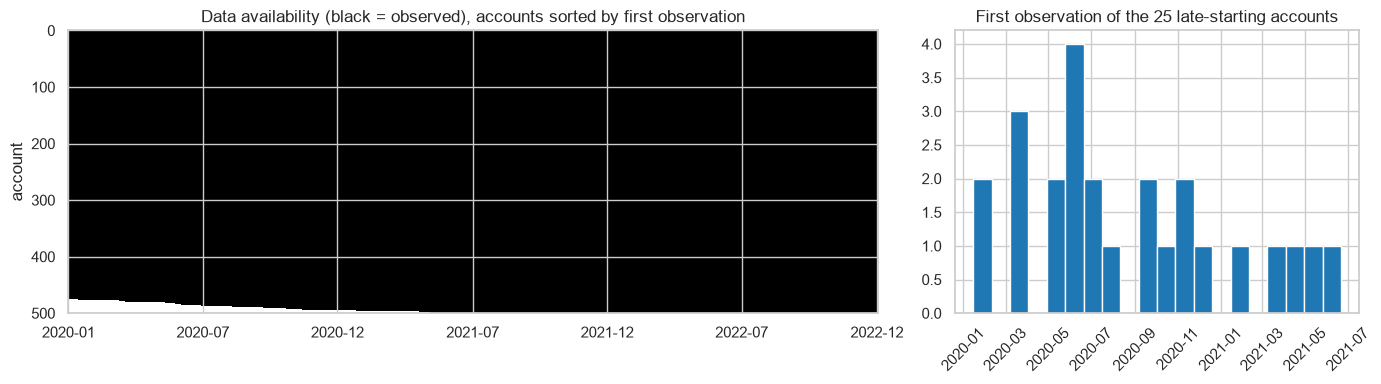

In [3]:
na = np.isnan(values)
n_leading = np.where(na.all(axis=1), na.shape[1], np.argmax(~na, axis=1))
n_trailing = np.where(na.all(axis=1), 0, np.argmax(~na[:, ::-1], axis=1))
n_interior = na.sum(axis=1) - n_leading - n_trailing

missing = pd.Series({
    "missing values": int(na.sum()),
    "% of all cells": round(100 * na.mean(), 2),
    "accounts with any missing": int(na.any(axis=1).sum()),
    "accounts entirely missing": int(na.all(axis=1).sum()),
    "leading missing (account not opened yet)": int(n_leading.sum()),
    "trailing missing (account closed)": int(n_trailing.sum()),
    "interior missing (gaps)": int(n_interior.sum()),
})
display(missing.to_frame("value"))

first_obs = pd.Series(dates[np.minimum(n_leading, len(dates) - 1)], index=raw.index, name="first_observation")
late = first_obs[first_obs > dates.min()]
save_result(missing.rename("value"), "02_missing_summary", "Missing values: totals by type (leading/trailing/interior)")
save_result(pd.DataFrame({"first_observation_raw_label": first_obs, "leading_missing_days": n_leading}),
            "02_first_observation", "Per account: first observed (raw) date and number of leading missing days")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
order = np.argsort(n_leading)
axes[0].imshow(~na[order], aspect="auto", cmap="Greys", interpolation="nearest",
               extent=[0, len(dates), len(order), 0])
ticks = np.linspace(0, len(dates) - 1, 7).astype(int)
axes[0].set_xticks(ticks, [dates[t].strftime("%Y-%m") for t in ticks])
axes[0].set(title="Data availability (black = observed), accounts sorted by first observation", ylabel="account")
if len(late):
    axes[1].hist(late, bins=20, color="tab:blue")
axes[1].set(title=f"First observation of the {len(late)} late-starting accounts")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

The answer is simple and reassuring. Every missing value sits at the beginning of a series: a small group of accounts
was opened during the period and has no history before that. There are no gaps in the middle and no account was
closed.

This settles our first decision. We will not fill these cells in, because inventing balances for an account that did
not exist would only add noise. Each account simply starts on its first day, and even the youngest one has months of
history before the end of the data, enough to be forecast.

## 3. A calendar that changes its rules

A balance only moves when money comes in or goes out. If we count, for each day, how many accounts saw their balance
change, we get a fingerprint of when the bank books transactions. We expected that fingerprint to say "weekdays", and
we looked at it by weekday and by month to confirm it.

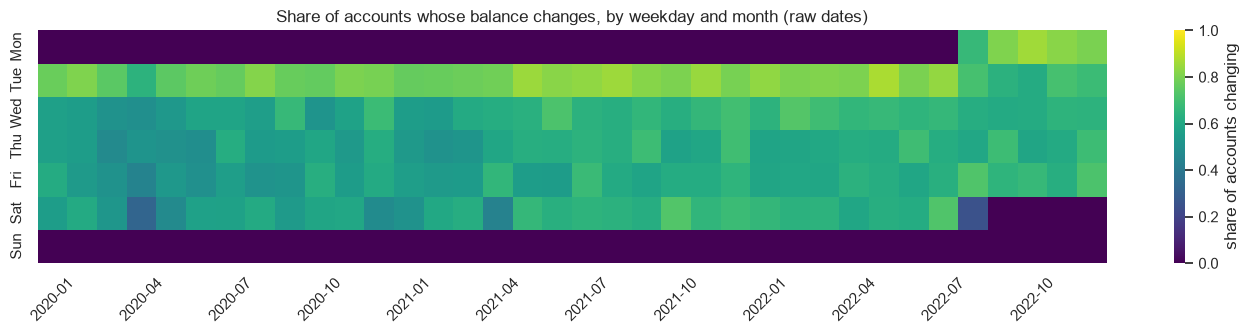

In [4]:
def change_share(wide):
    """Share of (observed) accounts whose balance changed vs the previous day, per date."""
    x = wide.to_numpy()
    d = np.diff(x, axis=1)
    valid = ~np.isnan(d)
    return pd.Series(((d != 0) & valid).sum(0) / np.maximum(valid.sum(0), 1), index=wide.columns[1:])


share_raw = change_share(raw)
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_month_weekday = (share_raw.groupby([share_raw.index.to_period("M"), share_raw.index.dayofweek]).mean()
                    .unstack().rename(columns=dict(enumerate(weekday_names))))
save_result(by_month_weekday.rename(index=str), "03_change_share_month_weekday_raw",
            "Raw labels: share of accounts whose balance changes, by month x weekday (shows the Aug-2022 switch)")
save_result(share_raw.rename("share_changing"), "03_change_share_daily_raw",
            "Raw labels: share of accounts whose balance changes, per date")

fig, ax = plt.subplots(figsize=(14, 3.5))
sns.heatmap(by_month_weekday.T, cmap="viridis", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "share of accounts changing"})
ax.set_xticks(np.arange(0, len(by_month_weekday), 3) + 0.5,
              [str(p) for p in by_month_weekday.index[::3]], rotation=45)
ax.set(title="Share of accounts whose balance changes, by weekday and month (raw dates)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

It did not say weekdays, and it did not say the same thing all the time. Until the beginning of August 2022 the
balances move from Tuesday to Saturday and never on Sundays or Mondays. From August 2022 onwards they move from Monday
to Friday and stay still at weekends.

The most natural explanation is that, in the first period, the balance written under day *D* is the closing balance
of the day before. Monday's transactions then appear on Tuesday's column and Friday's on Saturday's, which is exactly
the pattern we see. In August 2022 the convention switches to the closing balance of the same day.

This matters a lot. The 30 days we have to forecast follow the new convention, but 85% of our history follows the old
one. Left as it is, any model would learn a weekly rhythm shifted by one day. Before acting on this explanation we
looked for more evidence and for the exact moment of the switch.

In [5]:
# (a) Holidays: if label D = close of D-1, activity should drop on labels that FOLLOW a holiday (old convention).
pt_holidays = holidays.Portugal(years=range(dates.min().year, dates.max().year + 2))
old_conv = share_raw[share_raw.index < "2022-08-01"]
tue_sat = old_conv[(old_conv.index.dayofweek >= 1) & (old_conv.index.dayofweek <= 5)]
prev_is_holiday = np.array([(d - pd.Timedelta(days=1)) in pt_holidays for d in tue_sat.index])
same_is_holiday = np.array([d in pt_holidays for d in tue_sat.index])
holiday_check = pd.Series({
    "label after a holiday (old convention)": tue_sat[prev_is_holiday].mean(),
    "label on a holiday (old convention)": tue_sat[same_is_holiday].mean(),
    "other Tue-Sat labels": tue_sat[~prev_is_holiday & ~same_is_holiday].mean(),
}).round(3).rename("share of accounts changing")
save_result(holiday_check, "03_holiday_check_old_convention",
            "Old date convention: activity on labels after/on holidays (supports label D = close of D-1)")
display(holiday_check.to_frame())

# (b) The switch itself
window = raw.loc[:, "2022-08-02":"2022-08-09"]
display(window.head(8).round(2))
display(change_share(raw.loc[:, "2022-08-01":"2022-08-10"]).round(2).to_frame("share changing")
        .assign(weekday=lambda t: t.index.day_name()))

,share of accounts changing
label after a holiday (old convention),0.450
label on a holiday (old convention),0.662
other Tue-Sat labels,0.640


date,2022-08-02,2022-08-03,2022-08-04,2022-08-05,2022-08-06,2022-08-07,2022-08-08,2022-08-09
ACCOUNT_ID,,,,,,,,
1,7783.69,7661.65,8770.96,17541.92,8770.96,8770.96,7489.69,7489.69
2,4012.35,3815.50,3815.50,7631.00,3815.50,3815.50,3815.50,3815.50
3,522.57,448.45,81.31,340.68,139.27,139.27,128.46,35.14
4,37840.52,37840.52,37840.52,75681.04,37840.52,37840.52,37253.94,37090.45
5,12081.10,12837.17,12065.78,24129.04,12063.26,12063.26,12063.26,12032.51
6,989.72,989.72,835.78,1671.56,835.78,835.78,805.73,805.73
7,320.91,320.91,299.61,735.84,459.12,459.12,418.25,405.34
8,552.73,147.98,106.32,155.93,49.61,49.61,-34.45,-34.45


,share changing,weekday
date,,
2022-08-02,0.89,Tuesday
2022-08-03,0.65,Wednesday
2022-08-04,0.61,Thursday
2022-08-05,1.00,Friday
2022-08-06,1.00,Saturday
2022-08-07,0.00,Sunday
2022-08-08,0.86,Monday
2022-08-09,0.68,Tuesday
2022-08-10,0.64,Wednesday


Two pieces of evidence support the explanation. Under the old convention, activity drops on the day *after* a public
holiday rather than on the holiday itself, which is what we would expect if each column describes the previous day.
And around the switch the data shows exactly how it happened.

Looking at the first accounts in early August 2022, the column of 5 August stands out: every single account changes,
and the values are roughly twice as large as their neighbours. Account 1 shows 17 541.92, which is exactly 8 770.96
plus 8 770.96. That day holds the sum of two closing balances, Thursday's and Friday's, probably written twice during
the migration. Since Friday's balance is the next column, Thursday's can be recovered exactly by subtraction. The
column of Sunday 7 August, already under the new convention, equals Saturday's for every account, as it should when
nothing happens over a weekend.

With this we can rebuild a consistent calendar in three steps. We repair 5 August by subtracting the next day, we
move every column before the switch back by one day, and we fill the one empty Saturday this creates with Sunday's
balance. From here on every value is the closing balance of its own date.

,value
dates after realignment,2020-01-01 -> 2022-12-31 (1096 days)
repaired Thursday 2022-08-04: median |change| vs Wednesday,19.86
typical weekday median |change| (2022),14.81


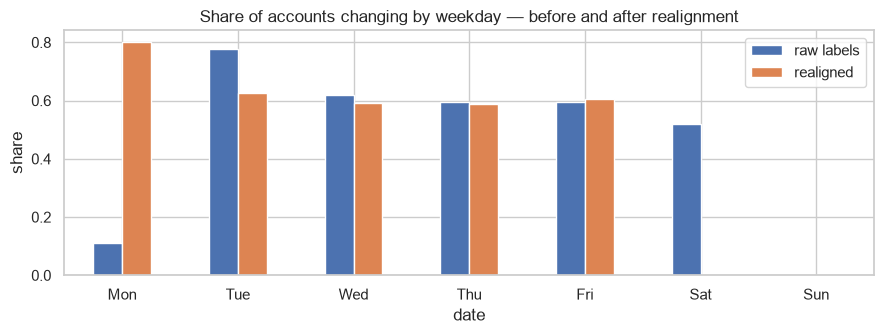

In [6]:
SWITCH_FIRST_NEW_LABEL = pd.Timestamp("2022-08-07")   # first label recorded with the same-day convention
CORRUPTED_LABEL = pd.Timestamp("2022-08-05")          # sum of two closing balances
NEXT_LABEL = pd.Timestamp("2022-08-06")


def realign_calendar(wide):
    """Return a frame where every column is the closing balance of that same date."""
    old = wide.loc[:, wide.columns < SWITCH_FIRST_NEW_LABEL].copy()
    new = wide.loc[:, wide.columns >= SWITCH_FIRST_NEW_LABEL]
    if CORRUPTED_LABEL in old.columns and NEXT_LABEL in old.columns:
        old[CORRUPTED_LABEL] = old[CORRUPTED_LABEL] - old[NEXT_LABEL]
    old.columns = old.columns - pd.Timedelta(days=1)
    out = pd.concat([old, new], axis=1)
    full = pd.date_range(out.columns.min(), out.columns.max(), freq="D")
    gaps = full.difference(out.columns)
    out = out.reindex(columns=full)
    for g in gaps:                       # weekend day left empty by the shift -> next day's balance
        out[g] = out[g + pd.Timedelta(days=1)]
    out.columns.name = "date"
    return out


bal = realign_calendar(raw)
share = change_share(bal)

repaired = bal[pd.Timestamp("2022-08-04")]
check = pd.Series({
    "dates after realignment": f"{bal.columns.min().date()} -> {bal.columns.max().date()} ({bal.shape[1]} days)",
    "repaired Thursday 2022-08-04: median |change| vs Wednesday": round(float((repaired - bal[pd.Timestamp("2022-08-03")]).abs().median()), 2),
    "typical weekday median |change| (2022)": round(float(bal.loc[:, "2022-01-01":"2022-12-31"].diff(axis=1).abs().median().median()), 2),
})
display(check.to_frame("value"))

compare = pd.DataFrame({
    "raw labels": share_raw.groupby(share_raw.index.dayofweek).mean(),
    "realigned": share.groupby(share.index.dayofweek).mean(),
}).rename(index=dict(enumerate(weekday_names)))
save_result(check.astype(str).rename("value"), "03_realignment_check", "Checks of the realigned calendar and repaired day")
save_result(compare, "03_weekday_activity_before_after", "Share of accounts changing by weekday: raw vs realigned")
compare.plot.bar(figsize=(9, 3.5), rot=0, title="Share of accounts changing by weekday — before and after realignment")
plt.ylabel("share"); plt.tight_layout(); plt.show()

After realignment the fingerprint is the one we expected from the start: balances change from Monday to Friday and
rest at weekends, over the whole three years, and the repaired Thursday looks like any other weekday. Everything that
follows uses this corrected data.

## 4. What a typical account looks like

With a calendar we can trust, we can describe the accounts themselves. They differ so much in size that a single
average would hide almost everything, so we describe each account separately and then look at how those descriptions
are spread across accounts. We treat the level of the balance and its daily changes separately, since they behave
very differently.

,count,mean,std,min,5%,25%,50%,75%,95%,max
mean,500.0,11531.30,105595.29,-1499.81,-108.07,183.41,723.40,3694.56,26466.24,2247008.97
median,500.0,8413.73,55953.67,-1732.27,-254.34,33.87,481.87,2577.30,21051.10,1056714.11
std,500.0,8877.70,111233.61,68.56,182.86,395.32,888.48,2630.32,16897.21,2472436.78
min,500.0,455.35,22903.58,-140167.78,-1563.48,-355.64,-147.14,57.08,5955.39,324740.99
max,500.0,37379.12,368436.94,381.13,919.27,2106.38,5430.85,17425.66,85631.52,8119331.47
skewness,500.0,1.96,3.55,-31.30,-0.57,0.63,1.34,2.62,7.79,21.20
excess_kurtosis,500.0,21.10,72.39,-1.82,-1.10,0.11,2.31,9.85,87.47,1015.08
share_negative,500.0,0.22,0.27,0.00,0.00,0.00,0.07,0.40,0.76,0.98
share_days_changed,500.0,0.46,0.11,0.28,0.30,0.37,0.46,0.54,0.63,0.70
cv,500.0,3.00,8.74,0.05,0.29,0.64,1.08,2.22,9.45,123.58


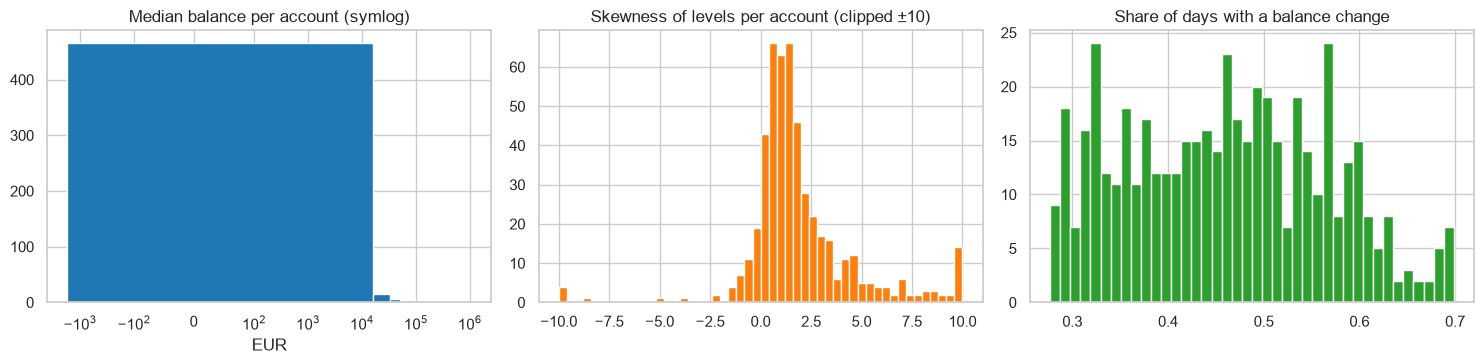

In [7]:
B = bal.to_numpy()
dB = np.diff(B, axis=1)

per_account = pd.DataFrame({
    "mean": np.nanmean(B, 1),
    "median": np.nanmedian(B, 1),
    "std": np.nanstd(B, 1),
    "min": np.nanmin(B, 1),
    "max": np.nanmax(B, 1),
    "skewness": stats.skew(B, axis=1, nan_policy="omit"),
    "excess_kurtosis": stats.kurtosis(B, axis=1, nan_policy="omit"),
    "share_negative": np.nanmean(np.where(np.isnan(B), np.nan, B < 0), 1),
    "share_days_changed": np.sum((dB != 0) & ~np.isnan(dB), 1) / np.sum(~np.isnan(dB), 1),
}, index=bal.index)
per_account["cv"] = per_account["std"] / per_account["mean"].abs()

display(per_account.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(per_account["median"], bins=60, color="tab:blue")
axes[0].set_xscale("symlog", linthresh=100); axes[0].set(title="Median balance per account (symlog)", xlabel="EUR")
axes[1].hist(per_account["skewness"].clip(-10, 10), bins=50, color="tab:orange")
axes[1].set(title="Skewness of levels per account (clipped ±10)")
axes[2].hist(per_account["share_days_changed"], bins=40, color="tab:green")
axes[2].set(title="Share of days with a balance change")
plt.tight_layout(); plt.show()

Many classical models, ARIMA among them, assume that the shocks hitting a series are roughly normal. We check that
assumption on the daily changes of each account, on business days only, with the Jarque–Bera test.

In [8]:
test_ids = sample_accounts(bal.index, MAX_TEST_ACCOUNTS)
business = (bal.columns[1:].dayofweek < 5)
jb_p = []
for acc in test_ids:
    x = np.diff(bal.loc[acc].dropna().to_numpy())
    x = x[business[-len(x):]] if len(x) else x
    jb_p.append(stats.jarque_bera(x).pvalue if len(x) > 30 else np.nan)
jb_p = pd.Series(jb_p, index=test_ids)
per_account["jarque_bera_p_changes"] = jb_p
save_result(per_account, "04_per_account_statistics",
            "Per account: mean, median, std, min, max, skewness, kurtosis, share negative, activity, CV, JB p-value")
save_result(per_account.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T, "04_per_account_statistics_summary",
            "Distribution across accounts of the per-account statistics")
print(f"Jarque-Bera rejects normality of daily changes (p < 0.05) for {100 * (jb_p < 0.05).mean():.1f}% "
      f"of {len(test_ids)} accounts")

Jarque-Bera rejects normality of daily changes (p < 0.05) for 100.0% of 500 accounts


The accounts span several orders of magnitude: some typical balances are a few euros, others hundreds of thousands.
Any model that learns from many accounts at once will therefore have to work on a scaled version of the balance. The
levels are skewed with heavy tails, and the daily changes are far from normal for every account we tested. That is
not surprising once we remember what a daily change is: on most days nothing happens and the change is exactly zero,
and on a few days a salary or a large transfer produces a big jump. Balances are piecewise constant, which already
suggests that simply carrying the recent level forward will be a strong benchmark.

## 5. The zero problem

The evaluation metric divides each error by the true balance. That is harmless for a balance of €5 000, but it is
undefined when the balance is exactly zero and explodes when it is close to zero. Since the organisers did not tell
us how they handle those cases, we need to know how often they occur.

In [9]:
obs = B[~np.isnan(B)]
last = B[:, -HORIZON:]
sign_type = np.select(
    [per_account["min"] > 0, per_account["max"] < 0],
    ["always positive", "always negative"], default="changes sign")
near_zero = pd.Series({
    "exact zeros": int((obs == 0).sum()),
    "% of balances negative": round(100 * (obs < 0).mean(), 2),
    f"% of balances with |x| < {NEAR_ZERO:.0f} EUR": round(100 * (np.abs(obs) < NEAR_ZERO).mean(), 2),
    "% of balances with |x| < 10 EUR": round(100 * (np.abs(obs) < 10).mean(), 2),
    f"% of last-{HORIZON}-day balances with |x| < {NEAR_ZERO:.0f} EUR": round(100 * np.nanmean(np.abs(last) < NEAR_ZERO), 2),
})
display(near_zero.to_frame("value"))
display(pd.Series(sign_type, index=bal.index).value_counts().to_frame("accounts"))
save_result(near_zero.rename("value"), "05_near_zero_summary", "Zeros, negatives and near-zero balances (MAPE risk)")
save_result(pd.Series(sign_type, index=bal.index, name="sign_type"), "05_sign_type_per_account",
            "Per account: always positive / always negative / changes sign")

# Illustration: the same absolute error (EUR 50) produces wildly different percentage errors
illus = pd.DataFrame({"actual": [5000, 500, 100, 20, 5, 1]})
illus["forecast"] = illus["actual"] + 50
illus["APE (%)"] = (100 * (illus["actual"] - illus["forecast"]).abs() / illus["actual"].abs()).round(1)
illus

,value
exact zeros,6.00
% of balances negative,22.12
% of balances with |x| < 100 EUR,17.02
% of balances with |x| < 10 EUR,2.43
% of last-30-day balances with |x| < 100 EUR,14.68


,accounts
changes sign,358
always positive,142


,actual,forecast,APE (%)
0,5000,5050,1.0
1,500,550,10.0
2,100,150,50.0
3,20,70,250.0
4,5,55,1000.0
5,1,51,5000.0


Exact zeros are rare, but balances close to zero are not: about one in six is within €100 of zero, about one in five
is negative, and most accounts cross zero at some point. These are overdrafts and credit lines, perfectly legitimate,
so our forecasts must be allowed to go negative.

The small table above shows why this dominates everything. The same €50 error is 1% on a €5 000 balance and 1 000% on
a €5 balance. A handful of near-zero days can therefore outweigh thousands of well-forecast ones in the official
score.

We will keep the official MAPE as the number that decides between models. To understand it, we will always report two
companions: the median MAPE across accounts, which describes the typical account, and the MAPE computed only on
balances of at least €100. When the official number is far above both, we will know the near-zero balances are to
blame. This also hints at a modelling idea for Sprint 2: when a balance might be close to zero, a smaller forecast in
absolute value is the safer bet, because over-forecasting a small balance is punished far more than the opposite.

## 6. Big moves

Heavy tails mean big jumps. We want to know whether they are errors to remove or behaviour to keep. Because most days
show no change at all, we measure how extreme a move is relative to the account's other, non-zero moves. We also
separate spikes, where money comes in and leaves again within a few days, from shifts that leave the balance at a
new level.

,value
non-zero daily changes,248673.0
% of non-zero changes with robust z > 5,14.2
% of non-zero changes with robust z > 10 (extreme),7.9
extreme moves reversed within 3 days (spikes),438.0
% of extreme moves that are spikes,2.2
accounts with at least one extreme move,497.0


,max |balance|
ACCOUNT_ID,
192,8119331.0
323,1152403.0
54,541167.0
371,487162.0
445,305199.0


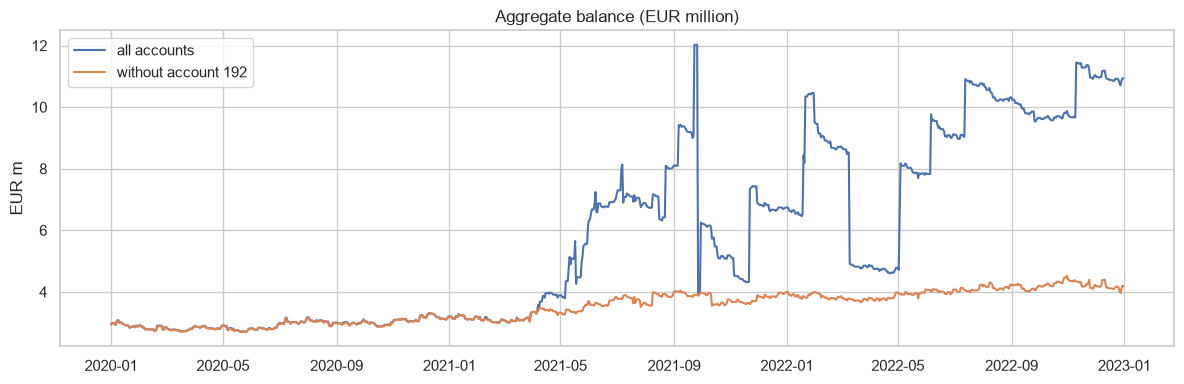

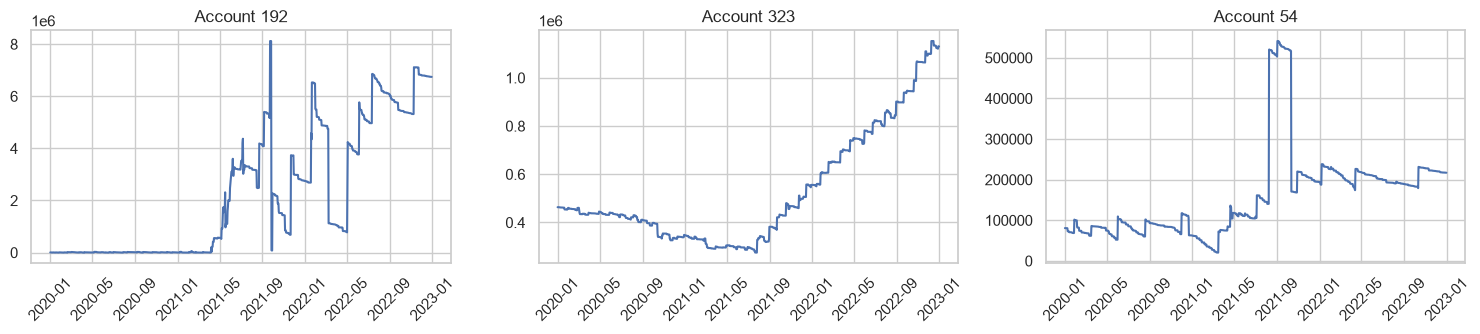

In [10]:
nonzero = np.where((dB != 0) & ~np.isnan(dB), dB, np.nan)
med = np.nanmedian(nonzero, 1, keepdims=True)
mad = 1.4826 * np.nanmedian(np.abs(nonzero - med), 1, keepdims=True)
z = np.abs(nonzero - med) / np.where(mad > 0, mad, np.nan)
big = z > 10

# spike = extreme move followed (within 3 days, to cover weekends) by a move that cancels >= 90% of it
spike = np.zeros_like(big)
for lag in (1, 2, 3):
    nxt = np.full_like(dB, np.nan); nxt[:, :-lag] = dB[:, lag:]
    spike |= big & (np.abs(dB + nxt) <= 0.1 * np.abs(dB))

n_nonzero = int(np.sum(~np.isnan(nonzero)))
extremes = pd.Series({
    "non-zero daily changes": n_nonzero,
    "% of non-zero changes with robust z > 5": round(100 * np.nansum(z > 5) / n_nonzero, 1),
    "% of non-zero changes with robust z > 10 (extreme)": round(100 * big.sum() / n_nonzero, 1),
    "extreme moves reversed within 3 days (spikes)": int(spike.sum()),
    "% of extreme moves that are spikes": round(100 * spike.sum() / max(big.sum(), 1), 1),
    "accounts with at least one extreme move": int(big.any(1).sum()),
})
display(extremes.to_frame("value"))

# Largest accounts and the effect of a single account on the aggregate
top = per_account["max"].abs().sort_values(ascending=False).head(5)
display(top.round(0).to_frame("max |balance|"))
save_result(extremes.rename("value"), "06_extremes_summary", "Extreme daily moves (robust z on non-zero changes) and spikes")
save_result(pd.DataFrame({"extreme_moves": big.sum(1), "spikes": spike.sum(1)}, index=bal.index),
            "06_extremes_per_account", "Per account: number of extreme moves and reversed spikes")
save_result(top.rename("max_abs_balance"), "06_top_accounts", "Accounts with the largest absolute balances")
total = bal.sum(0)
total_wo_top = bal.drop(index=top.index[:1]).sum(0)
fig, ax = plt.subplots()
ax.plot(total.index, total / 1e6, label="all accounts")
ax.plot(total_wo_top.index, total_wo_top / 1e6, label=f"without account {top.index[0]}")
ax.set(title="Aggregate balance (EUR million)", ylabel="EUR m"); ax.legend(); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharex=True)
for ax, acc in zip(axes, top.index[:3]):
    ax.plot(bal.columns, bal.loc[acc]); ax.set_title(f"Account {acc}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

Big moves are everywhere: almost every account has some, and they are a sizeable share of all non-zero changes. Very
few are reversed spikes, though. Most of them move the account to a new level and stay there: a salary, a large
transfer, an account starting to be used differently. This is real behaviour, so we keep it. Removing it would make
the history look calmer than the future will be.

The largest accounts deserve a word. One of them grows from a few thousand euros to several million, and on its own
it changes the shape of the total balance of all accounts. The total is therefore a poor picture of the typical
client, and it is one more reason to scale each account before letting a model learn from many of them together.

# Part B · The rhythm of the balances

## 7. Weeks, months and holidays

Money moves to a calendar: salaries at the end of the month, pensions on fixed days, debits at the beginning, nothing
at weekends. We relate the daily changes to the day of the week, the day of the month, the month and the Portuguese
public holidays. To compare accounts of very different sizes we express each change relative to the account's typical
balance, and we count a "large inflow" or "large outflow" when the balance moves by more than 20% of that level in a
single day.

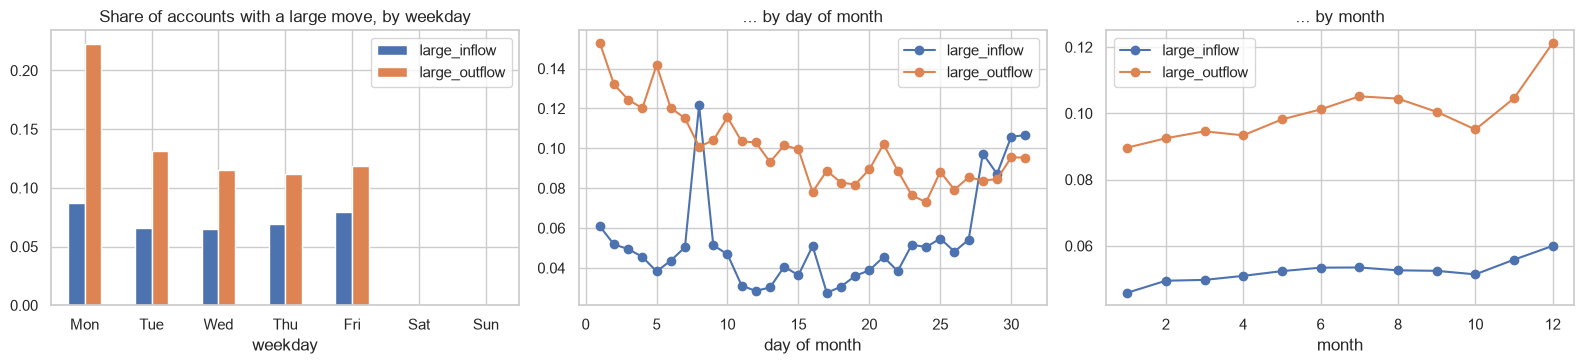

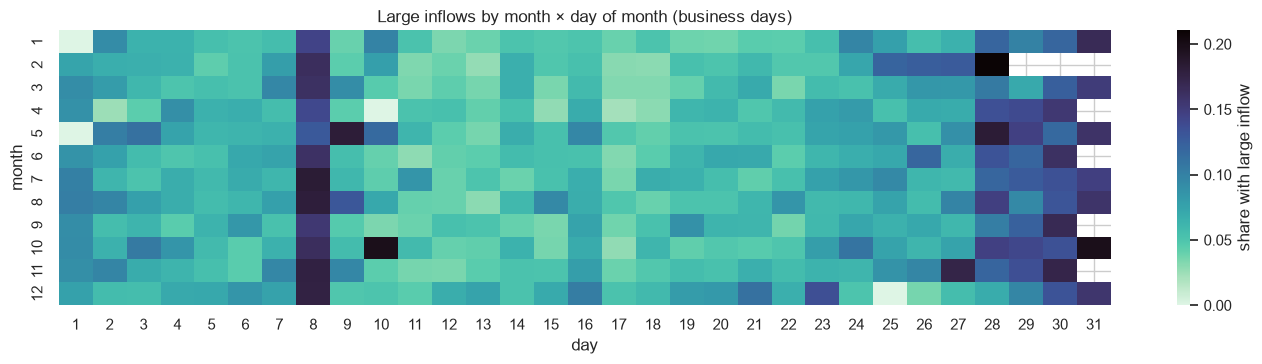

In [11]:
typical = np.nanmedian(np.abs(B), 1, keepdims=True)
rel = dB / np.where(typical > 0, typical, np.nan)          # relative daily change
rel = np.clip(rel, -5, 5)                                  # limit the influence of extreme relative moves
cd = bal.columns[1:]
inflow = (rel > 0.2)                                       # "large inflow": +20% of the typical balance in a day
outflow = (rel < -0.2)

cal = pd.DataFrame({
    "weekday": cd.dayofweek, "day": cd.day, "month": cd.month,
    "share_changing": share.values,
    "large_inflow": np.nanmean(np.where(np.isnan(rel), np.nan, inflow), 0),
    "large_outflow": np.nanmean(np.where(np.isnan(rel), np.nan, outflow), 0),
    "mean_rel_change": np.nanmean(rel, 0),
}, index=cd)
save_result(cal, "07_calendar_daily", "Per date: weekday/day/month, share changing, share with large inflow/outflow, mean relative change")
for g in ["weekday", "day", "month"]:
    save_result(cal.groupby(g)[["share_changing", "large_inflow", "large_outflow", "mean_rel_change"]].mean(),
                f"07_calendar_by_{g}", f"Calendar effects aggregated by {g}")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
cal.groupby("weekday")[["large_inflow", "large_outflow"]].mean().rename(index=dict(enumerate(weekday_names))).plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Share of accounts with a large move, by weekday")
cal.groupby("day")[["large_inflow", "large_outflow"]].mean().plot(ax=axes[1], marker="o")
axes[1].set(title="... by day of month", xlabel="day of month")
cal.groupby("month")[["large_inflow", "large_outflow"]].mean().plot(ax=axes[2], marker="o")
axes[2].set(title="... by month", xlabel="month")
plt.tight_layout(); plt.show()

heat = cal[cal.weekday < 5].pivot_table(index="month", columns="day", values="large_inflow", aggfunc="mean")
fig, ax = plt.subplots(figsize=(14, 3.8))
sns.heatmap(heat, cmap="mako_r", ax=ax, cbar_kws={"label": "share with large inflow"})
ax.set(title="Large inflows by month × day of month (business days)"); plt.tight_layout(); plt.show()

The pictures suggest clear patterns, and we check that they are not chance with the Kruskal–Wallis test, a
comparison of groups that does not assume normal data.

In [12]:
pts = pd.DataFrame({"rel": rel.ravel(),
                    "weekday": np.tile(cd.dayofweek, rel.shape[0]),
                    "day": np.tile(cd.day, rel.shape[0]),
                    "month": np.tile(cd.month, rel.shape[0])}).dropna()
pts = pts[pts.weekday < 5]
if len(pts) > 2_000_000:
    pts = pts.sample(2_000_000, random_state=RANDOM_STATE)
kw = {}
for g in ["weekday", "day", "month"]:
    groups = [v.to_numpy() for _, v in pts.groupby(g)["rel"]]
    h, p = stats.kruskal(*groups)
    kw[g] = {"H statistic": round(h, 1), "p-value": p}
kw = pd.DataFrame(kw).T
display(kw)

# Holidays (business days only)
bd = cal[cal.weekday < 5]
is_hol = np.array([d in pt_holidays for d in bd.index])
holiday_effect = pd.DataFrame({"holiday": bd[is_hol][["share_changing", "large_inflow"]].mean(),
                               "normal business day": bd[~is_hol][["share_changing", "large_inflow"]].mean()}).round(3)
display(holiday_effect)
save_result(kw, "07_kruskal_wallis", "Kruskal-Wallis tests of relative daily change by weekday, day of month, month")
save_result(holiday_effect, "07_holiday_effect", "Activity on Portuguese public holidays vs normal business days")

,H statistic,p-value
weekday,6555.6,0.000000e+00
day,3649.2,0.000000e+00
month,442.6,5.333444e-88


,holiday,normal business day
share_changing,0.508,0.647
large_inflow,0.059,0.074


The weekly rhythm is now the expected one: money moves on business days only. Monday is the busiest day, because it
absorbs everything that happened over the weekend, and Friday comes second.

The monthly rhythm is richer. Large inflows peak in the last days of the month, which is when most salaries are
paid, and there is a second, sharp peak on the 8th, which matches the date on which Social Security pensions are
usually paid in Portugal. Large outflows cluster in the first days of the month, when rents, loan instalments and
direct debits leave the accounts. Holidays are quieter than ordinary business days. The month of the year matters
much less: December brings slightly more inflows and January the fewest.

So the calendar our models need is a weekly one (business days against weekends and holidays) and a monthly one
(end of month, the 8th, the first days). The window we will forecast starts right after Christmas and includes a turn
of the month, so both rhythms will be at work.

## 8. A few accounts up close

Statistics summarise; pictures show. Here are nine accounts chosen at random.

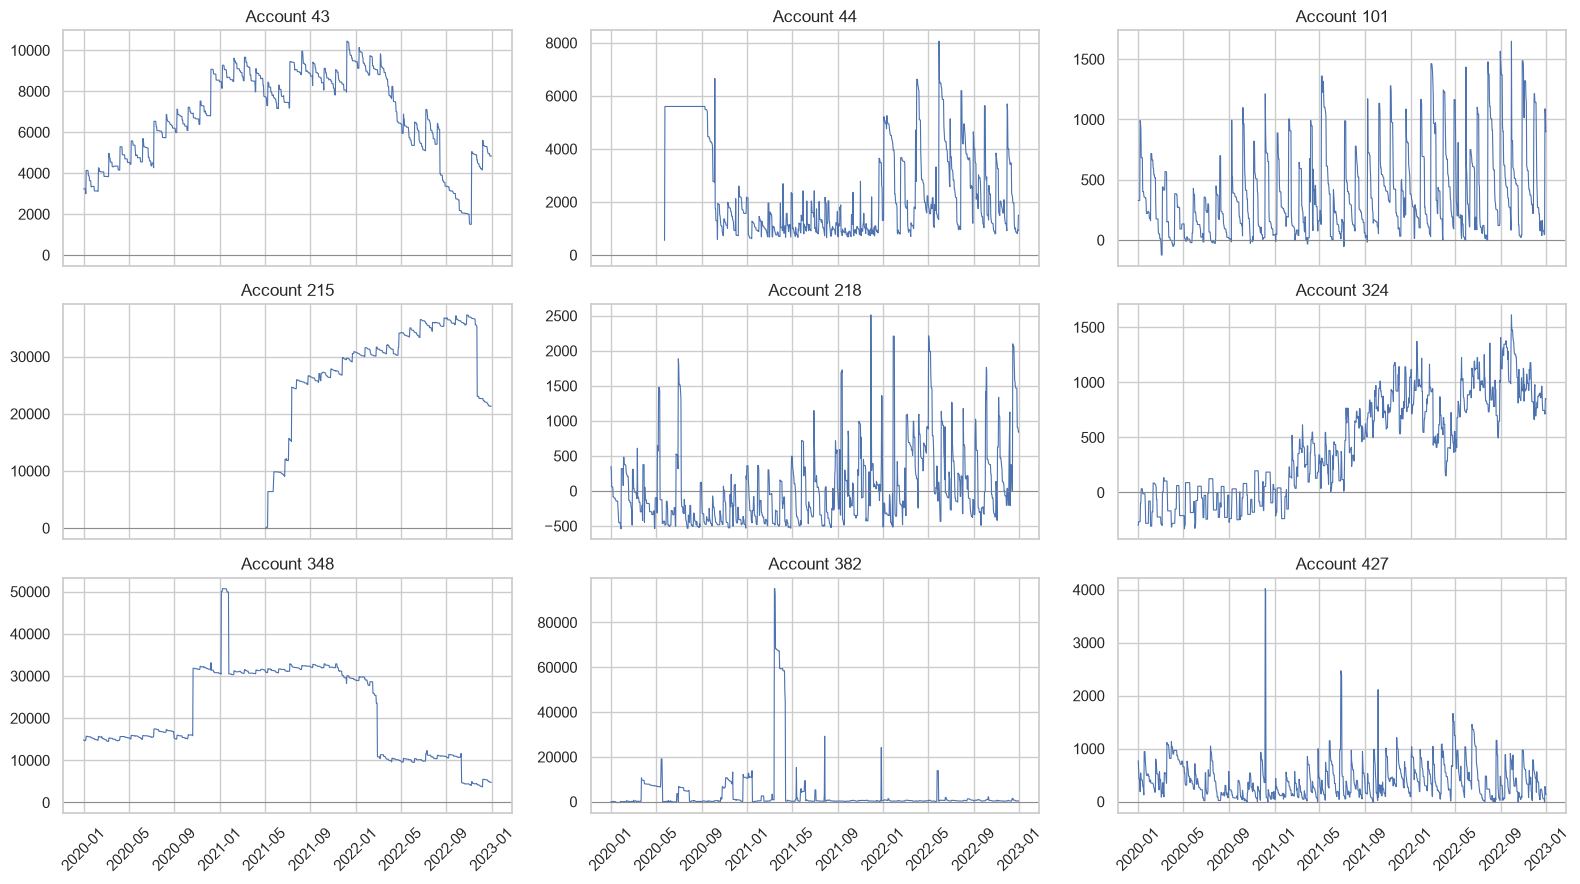

In [13]:
examples = sample_accounts(bal.index, 9)
fig, axes = plt.subplots(3, 3, figsize=(16, 9), sharex=True)
for ax, acc in zip(axes.ravel(), examples):
    ax.plot(bal.columns, bal.loc[acc], lw=0.8)
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(f"Account {acc}")
for ax in axes[-1]:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

A few shapes keep appearing. Some accounts draw a saw-tooth, rising on payday and sliding down as the month's
spending goes out. Others stay flat for long stretches, jump to a new level and stay there. Some live around zero,
moving in and out of overdraft. These shapes will come back when we group the accounts in section 15.

## 9. Separating trend from cycles

To measure how much of the movement belongs to each rhythm we decompose the series with MSTL, which splits a series
into a trend, a weekly cycle, a monthly cycle and what is left. Because a few very large accounts dominate the total,
we decompose the median balance across accounts, a stand-in for the typical client, and then repeat the exercise
account by account to measure the strength of each component.

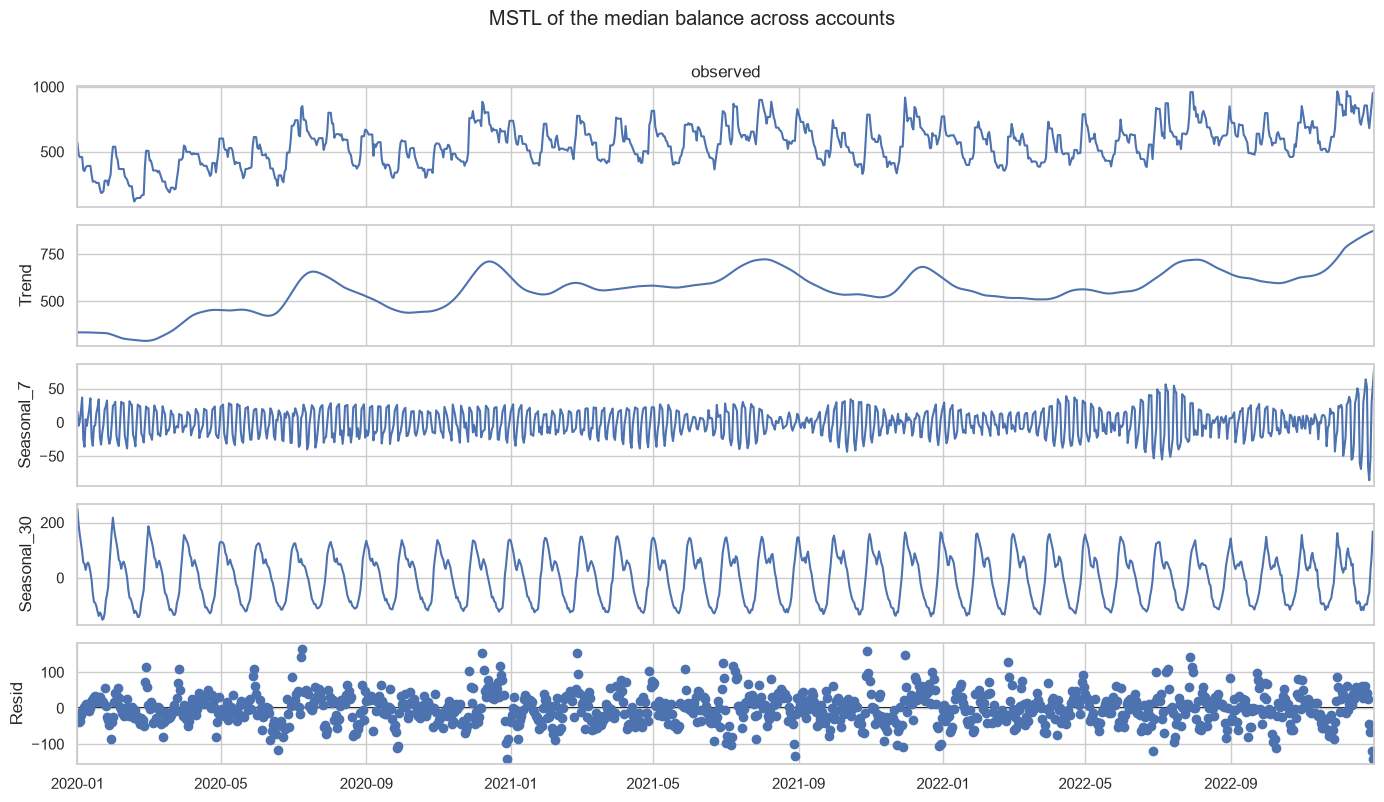

,median account (series),per-account (median of strengths)
trend,0.874,0.831
weekly (7),0.201,0.095
monthly (30),0.813,0.359


In [14]:
typical_series = bal.median(axis=0)
mstl = MSTL(typical_series, periods=(7, 30)).fit()
fig = mstl.plot(); fig.set_size_inches(14, 8); fig.suptitle("MSTL of the median balance across accounts", y=1.0)
plt.tight_layout(); plt.show()

# Strength of each component (Hyndman & Athanasopoulos): 1 - Var(resid) / Var(component + resid)
def strength(component, resid):
    return max(0.0, 1 - np.var(resid) / np.var(component + resid))


def component_strengths(series):
    res = MSTL(series, periods=(7, 30)).fit()
    return {"trend": strength(res.trend, res.resid),
            "weekly (7)": strength(res.seasonal["seasonal_7"], res.resid),
            "monthly (30)": strength(res.seasonal["seasonal_30"], res.resid)}


strengths = {}
for acc in sample_accounts(bal.index, MAX_TEST_ACCOUNTS):
    s = bal.loc[acc].dropna()
    if len(s) >= 120:
        strengths[acc] = component_strengths(s)
strengths = pd.DataFrame(strengths).T
strength_summary = pd.concat({"median account (series)": pd.Series(component_strengths(typical_series)),
                              "per-account (median of strengths)": strengths.median()}, axis=1).round(3)
display(strength_summary)
save_result(strength_summary, "09_mstl_strength_summary", "MSTL component strengths: median-account series and per-account median")
save_result(strengths, "09_mstl_strength_per_account", "Per account (sample): strength of trend, weekly and monthly components")
save_result(pd.DataFrame({"observed": typical_series, "trend": mstl.trend, "seasonal_7": mstl.seasonal["seasonal_7"],
                          "seasonal_30": mstl.seasonal["seasonal_30"], "resid": mstl.resid}),
            "09_mstl_median_account", "MSTL decomposition of the cross-sectional median balance")

The trend carries most of the movement. The monthly cycle is clearly stronger than the weekly one, which makes sense:
the weekly effect is mostly "nothing happens at weekends", important for daily forecasts but small in size. Account
by account the strength of the monthly cycle varies a lot. Some clients follow it closely and others not at all,
which argues for models fitted to each account, or at least to each group of accounts, rather than one seasonal
pattern for everyone.

## 10. Is there a stable mean?

Many forecasting models need a stationary series, one that fluctuates around a stable mean. Two tests look at this
from opposite sides: ADF starts by assuming the series wanders without a fixed mean, KPSS starts by assuming it is
stationary. We run both, on the balances and on their daily changes.

In [15]:
def stationarity_tests(x):
    out = {}
    for name, series in (("level", x), ("diff", np.diff(x))):
        try:
            out[f"adf_p_{name}"] = adfuller(series, autolag="AIC")[1]
            out[f"kpss_p_{name}"] = kpss(series, regression="c", nlags="auto")[1]
        except Exception:
            out[f"adf_p_{name}"] = out[f"kpss_p_{name}"] = np.nan
    return out


st = pd.DataFrame({acc: stationarity_tests(bal.loc[acc].dropna().to_numpy()) for acc in test_ids}).T


def classify(adf_p, kpss_p, alpha=0.05):
    if adf_p < alpha and kpss_p >= alpha:
        return "stationary (both agree)"
    if adf_p >= alpha and kpss_p < alpha:
        return "unit root (both agree)"
    if adf_p < alpha and kpss_p < alpha:
        return "conflicting: difference-stationary / level shifts"
    return "inconclusive"


st["levels"] = [classify(a, k) for a, k in zip(st.adf_p_level, st.kpss_p_level)]
st["first differences"] = [classify(a, k) for a, k in zip(st.adf_p_diff, st.kpss_p_diff)]
st_summary = pd.concat([st["levels"].value_counts(normalize=True), st["first differences"].value_counts(normalize=True)],
                       axis=1).fillna(0).mul(100).round(1).rename_axis("% of accounts")
display(st_summary)
save_result(st, "10_stationarity_per_account", "Per account: ADF and KPSS p-values (levels, differences) and classification")
save_result(st_summary, "10_stationarity_summary", "% of accounts per stationarity class, levels vs first differences")

,proportion,proportion
% of accounts,,
conflicting: difference-stationary / level shifts,47.8,1.0
unit root (both agree),29.4,0.0
stationary (both agree),21.4,99.0
inconclusive,1.4,0.0


On the balances themselves the two tests disagree for about half of the accounts. That is the typical signature of a
series that is stable for a while and then jumps to a new level, exactly what we saw in sections 6 and 8. On the
daily changes the verdict is unanimous: practically every account is stationary once differenced.

For ARIMA models this means one difference (d = 1). For models working on the level itself, the level must be allowed
to move, as in exponential smoothing.

## 11. How much does yesterday tell us about today?

The autocorrelation function measures how strongly a series is related to its own past; the partial autocorrelation
removes the intermediate days. We look at both for the median balance and then at the daily changes of every
account.

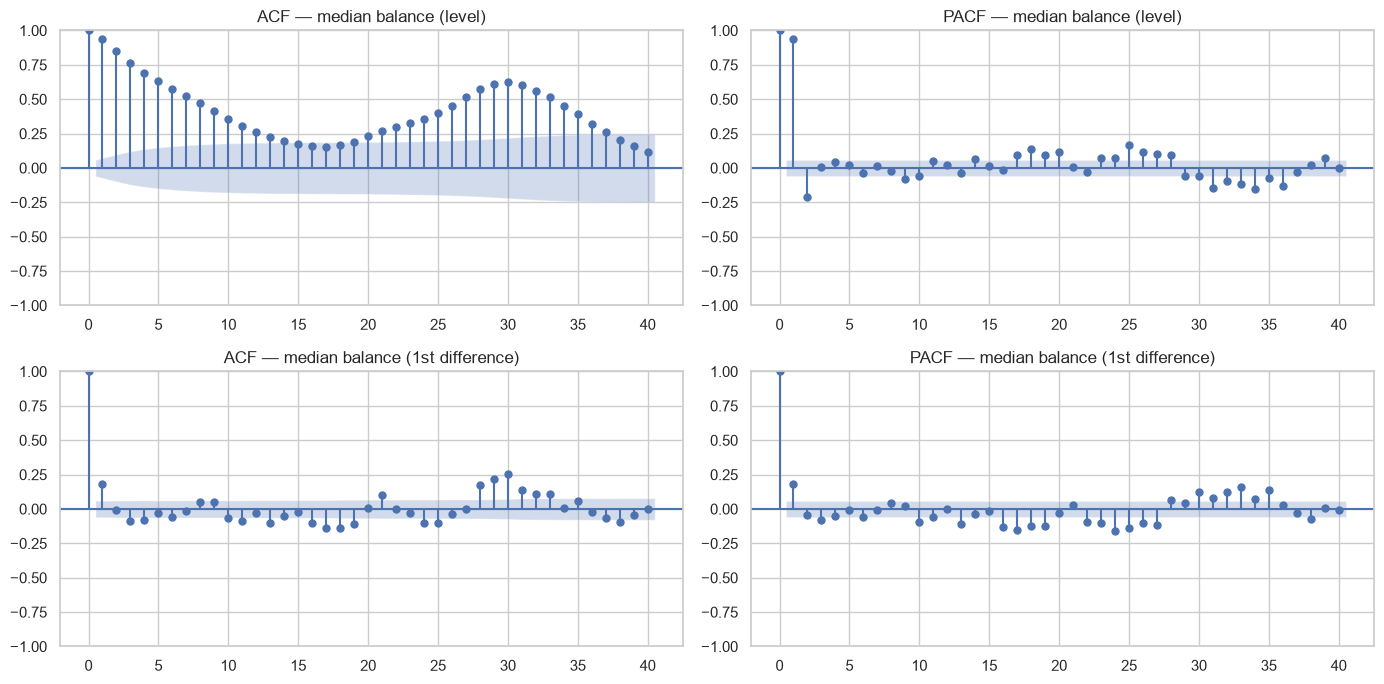

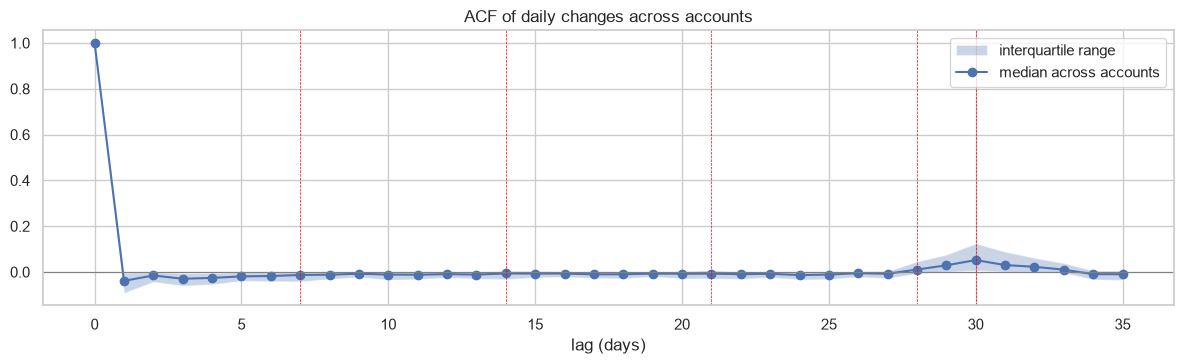

Ljung-Box rejects 'no autocorrelation' in daily changes: lag 7 -> 66.0% of accounts, lag 30 -> 83.4%


In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
plot_acf(typical_series, lags=40, ax=axes[0, 0], title="ACF — median balance (level)")
plot_pacf(typical_series, lags=40, ax=axes[0, 1], title="PACF — median balance (level)", method="ywm")
plot_acf(typical_series.diff().dropna(), lags=40, ax=axes[1, 0], title="ACF — median balance (1st difference)")
plot_pacf(typical_series.diff().dropna(), lags=40, ax=axes[1, 1], title="PACF — median balance (1st difference)", method="ywm")
plt.tight_layout(); plt.show()

NLAGS = 35
acfs, lb7, lb30, acf_ids = [], [], [], []
for acc in test_ids:
    x = np.diff(bal.loc[acc].dropna().to_numpy())
    if np.std(x) == 0:
        continue
    acf_ids.append(acc)
    acfs.append(acf(x, nlags=NLAGS, fft=True))
    lb = acorr_ljungbox(x, lags=[7, 30])
    lb7.append(lb["lb_pvalue"].iloc[0]); lb30.append(lb["lb_pvalue"].iloc[1])
acfs = np.array(acfs)
save_result(pd.DataFrame(acfs, index=pd.Index(acf_ids, name="ACCOUNT_ID"), columns=[f"lag_{l}" for l in range(NLAGS + 1)]),
            "11_acf_changes_per_account", "Per account: ACF of daily changes, lags 0-35")
save_result(pd.DataFrame({"median": np.median(acfs, 0), "p25": np.percentile(acfs, 25, 0), "p75": np.percentile(acfs, 75, 0)},
                         index=pd.Index(range(NLAGS + 1), name="lag")),
            "11_acf_changes_summary", "Median and IQR across accounts of the ACF of daily changes")
save_result(pd.DataFrame({"ljung_box_p_lag7": lb7, "ljung_box_p_lag30": lb30}, index=pd.Index(acf_ids, name="ACCOUNT_ID")),
            "11_ljung_box_per_account", "Per account: Ljung-Box p-values on daily changes (lags 7 and 30)")
save_result(pd.DataFrame({"acf": acf(typical_series, nlags=40), "pacf": pacf(typical_series, nlags=40),
                          "acf_diff": acf(typical_series.diff().dropna(), nlags=40),
                          "pacf_diff": pacf(typical_series.diff().dropna(), nlags=40)},
                         index=pd.Index(range(41), name="lag")),
            "11_acf_pacf_median_account", "ACF/PACF of the median-account series, levels and first differences")
fig, ax = plt.subplots(figsize=(12, 3.8))
lags = np.arange(NLAGS + 1)
ax.fill_between(lags, np.percentile(acfs, 25, 0), np.percentile(acfs, 75, 0), alpha=0.3, label="interquartile range")
ax.plot(lags, np.median(acfs, 0), marker="o", label="median across accounts")
ax.axhline(0, color="grey", lw=0.8)
for l in (7, 14, 21, 28, 30):
    ax.axvline(l, color="red", lw=0.5, ls="--")
ax.set(title="ACF of daily changes across accounts", xlabel="lag (days)"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Ljung-Box rejects 'no autocorrelation' in daily changes: lag 7 -> {100 * np.mean(np.array(lb7) < 0.05):.1f}% "
      f"of accounts, lag 30 -> {100 * np.mean(np.array(lb30) < 0.05):.1f}%")

The balance has a long memory: today's level is very close to yesterday's, and the partial autocorrelation is almost
entirely at the first lag, the classic picture of a random walk. The daily changes, by contrast, carry little memory:
a slight tendency to reverse in the following days, and a small bump around 28 to 31 days that is the monthly cycle
showing through. There is no clear weekly bump in the changes, because the weekly effect is an absence of movement
rather than a repeated amount. The Ljung–Box test confirms that most accounts keep some structure after
differencing.

This points to ARIMA models with one difference and short AR or MA terms, with the monthly cycle brought in through
the calendar rather than through a seasonal lag of 7.

## 12. Calm and agitated periods

Some series alternate between calm weeks and agitated ones. The ARCH test checks whether large changes tend to follow
large changes.

ARCH-LM rejects homoscedasticity for 36.8% of accounts


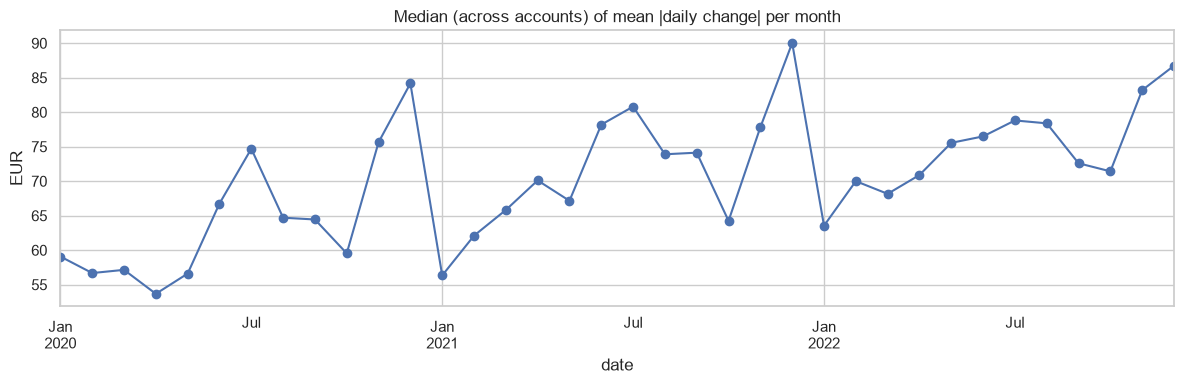

In [17]:
arch_p = []
for acc in test_ids:
    x = np.diff(bal.loc[acc].dropna().to_numpy())
    arch_p.append(het_arch(x, nlags=7)[1] if np.std(x) > 0 else np.nan)
arch_p = pd.Series(arch_p, index=test_ids)
print(f"ARCH-LM rejects homoscedasticity for {100 * (arch_p < 0.05).mean():.1f}% of accounts")

monthly_vol = pd.DataFrame(np.abs(dB), columns=cd).T.groupby(cd.to_period("M")).mean().median(axis=1)
save_result(arch_p.rename("arch_lm_p"), "12_arch_per_account", "Per account: ARCH-LM p-value on daily changes (7 lags)")
save_result(monthly_vol.rename(index=str).rename("median_mean_abs_change"), "12_monthly_volatility",
            "Per month: median across accounts of the mean absolute daily change")
monthly_vol.plot(title="Median (across accounts) of mean |daily change| per month", marker="o")
plt.ylabel("EUR"); plt.tight_layout(); plt.show()

About a third of the accounts show this clustering. It matters for the width of prediction intervals and it is one
more argument to give recent data more weight, but it is not strong enough to justify volatility models such as GARCH
for a point forecast.

## 13. Three years in comparison

The data covers 2020, 2021 and 2022: a pandemic year, a recovery year and a year of high inflation. We compare them
on a few simple measures.

In [18]:
yearly = pd.DataFrame({
    "median balance (median account)": bal.median(0).groupby(bal.columns.year).mean(),
    "share of balances negative (%)": (bal < 0).where(bal.notna()).mean(0).groupby(bal.columns.year).mean() * 100,
    "share of accounts changing per business day": share[share.index.dayofweek < 5].groupby(share.index[share.index.dayofweek < 5].year).mean(),
    "active accounts": bal.notna().sum(0).groupby(bal.columns.year).max(),
}).round(3)
save_result(yearly, "13_yearly_summary", "Per year: typical balance, share negative, activity, active accounts")
yearly

,median balance (median account),share of balances negative (%),share of accounts changing per business day,active accounts
date,,,,
2020,472.617,28.302231,0.595,495
2021,596.225,22.329808,0.654,500
2022,613.656,15.931507,0.678,500


The typical account grows over the three years, the share of negative balances falls clearly, and the accounts
become more active every year. The economy left its mark, but the biggest break we found is not economic at all: it
is the change in the date convention of section 3, which we have already corrected. For forecasting, the most recent
months are the most representative.

# Part C · Accounts side by side

## 14. Do accounts move together?

If accounts moved together, the history of one could help forecast another. Comparing balances directly would be
misleading, because any two accounts that both grow over time look correlated even if they have nothing in common. We
therefore compare their daily changes, showing the balances only as a contrast.

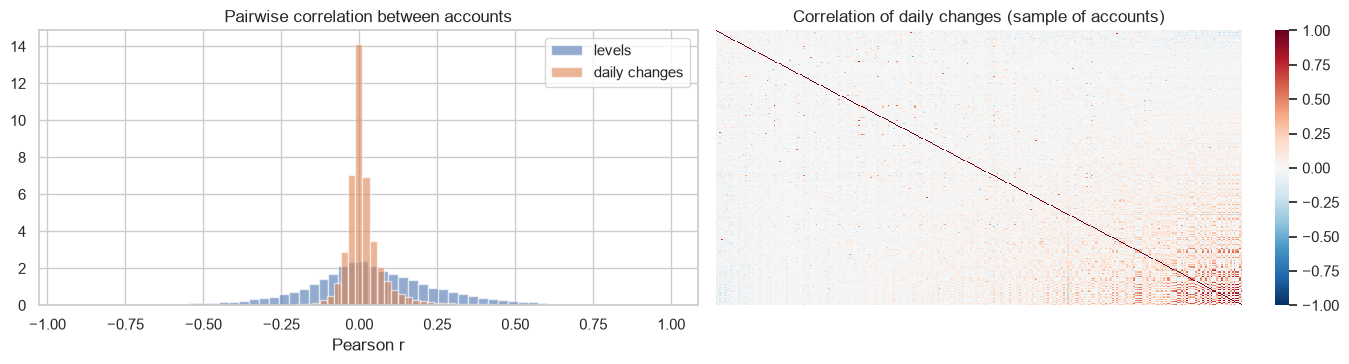

,levels,daily changes
count,44850.000,44850.000
mean,0.039,0.017
std,0.227,0.078
min,-0.931,-0.471
5%,-0.329,-0.060
50%,0.027,0.002
95%,0.429,0.140
max,0.989,0.903


In [19]:
corr_ids = sample_accounts(bal.index, MAX_CORR_ACCOUNTS)
changes = bal.loc[corr_ids].T.diff().iloc[1:]
changes = changes.loc[changes.index.dayofweek < 5]           # business days only
corr_changes = changes.corr(min_periods=60).to_numpy()
corr_levels = bal.loc[corr_ids].T.corr(min_periods=60).to_numpy()
iu = np.triu_indices_from(corr_changes, 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(corr_levels[iu], bins=60, alpha=0.6, label="levels", density=True)
axes[0].hist(corr_changes[iu], bins=60, alpha=0.6, label="daily changes", density=True)
axes[0].set(title="Pairwise correlation between accounts", xlabel="Pearson r"); axes[0].legend()
order_idx = np.argsort(np.nan_to_num(corr_changes).mean(0))
sns.heatmap(corr_changes[np.ix_(order_idx, order_idx)], cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1],
            xticklabels=False, yticklabels=False)
axes[1].set(title="Correlation of daily changes (sample of accounts)")
plt.tight_layout(); plt.show()
corr_summary = pd.DataFrame({
    "levels": pd.Series(corr_levels[iu]).describe(percentiles=[0.05, 0.5, 0.95]),
    "daily changes": pd.Series(corr_changes[iu]).describe(percentiles=[0.05, 0.5, 0.95]),
}).round(3)
display(corr_summary)
pairs = pd.DataFrame({"account_a": corr_ids[iu[0]], "account_b": corr_ids[iu[1]],
                      "corr_changes": corr_changes[iu], "corr_levels": corr_levels[iu]})
top_pairs = pairs.reindex(pairs.corr_changes.abs().sort_values(ascending=False).index).head(50)
save_result(corr_summary, "14_correlation_summary", "Distribution of pairwise correlations: levels vs daily changes (sample)")
save_result(top_pairs, "14_top_correlated_pairs", "50 account pairs with the strongest correlation of daily changes", index=False)

The accounts barely move together. The typical correlation between the daily changes of two accounts is practically
zero, with only a few pairs standing out. The correlations between balances spread widely in both directions, which
is mostly the illusion we were warned about.

A model that ties accounts together, such as a VAR, has nothing to work with here. What accounts share is the
calendar, not their shocks. The useful way to learn across accounts is a global model fed with calendar information,
while each account keeps its own dynamics.

## 15. Four kinds of accounts

We saw several shapes in section 8. To make them usable we group the accounts with a few simple rules applied to their
last twelve months, the period closest to what we will forecast: how often the balance moves, how often it is near
zero or negative, and how much it varies relative to its level.

,accounts,activity,share_near_zero,share_negative,cv,median_balance,% accounts
segment,,,,,,,
dormant,1,0.049,0.984,0.775,7.748,-1.690,0.2
near-zero / overdraft,195,0.495,0.400,0.332,1.769,49.440,39.0
stable positive,138,0.456,0.000,0.000,0.253,6847.485,27.6
volatile positive,166,0.534,0.047,0.005,0.764,809.410,33.2


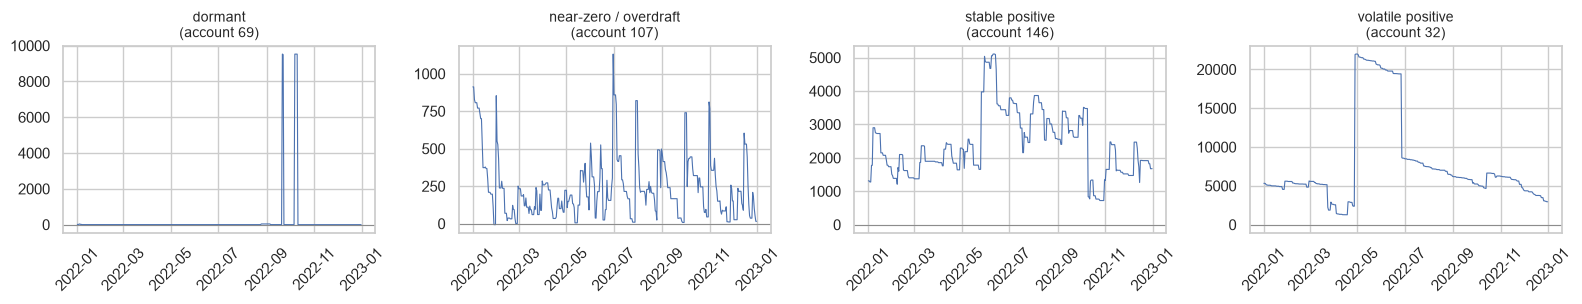

In [20]:
recent = bal.loc[:, bal.columns > bal.columns.max() - pd.Timedelta(days=365)]
R = recent.to_numpy(); dR = np.diff(R, axis=1)
feat = pd.DataFrame({
    "activity": np.sum((dR != 0) & ~np.isnan(dR), 1) / np.sum(~np.isnan(dR), 1),
    "share_near_zero": np.nanmean(np.where(np.isnan(R), np.nan, np.abs(R) < NEAR_ZERO), 1),
    "share_negative": np.nanmean(np.where(np.isnan(R), np.nan, R < 0), 1),
    "cv": np.nanstd(R, 1) / np.abs(np.nanmean(R, 1)),
    "median_balance": np.nanmedian(R, 1),
}, index=bal.index)


def segment(r):
    if r.activity < 0.05:
        return "dormant"
    if r.share_near_zero > 0.25 or r.share_negative > 0.25:
        return "near-zero / overdraft"
    if r.cv < 0.5:
        return "stable positive"
    return "volatile positive"


feat["segment"] = feat.apply(segment, axis=1)
seg_summary = feat.groupby("segment").agg(
    accounts=("activity", "size"), activity=("activity", "median"), share_near_zero=("share_near_zero", "median"),
    share_negative=("share_negative", "median"), cv=("cv", "median"), median_balance=("median_balance", "median"))
seg_summary["% accounts"] = (100 * seg_summary.accounts / len(feat)).round(1)
display(seg_summary.round(3))
save_result(feat, "15_segments_per_account", "Per account: last-12-month features and segment")
save_result(seg_summary, "15_segment_summary", "Per segment: number of accounts and median features")

fig, axes = plt.subplots(1, len(seg_summary), figsize=(16, 3.2))
for ax, seg in zip(np.atleast_1d(axes), seg_summary.index):
    ids = feat.index[feat.segment == seg]
    acc = ids[rng.integers(len(ids))]
    ax.plot(recent.columns, recent.loc[acc], lw=0.8); ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(f"{seg}\n(account {acc})", fontsize=10); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

The grouping already shows where the difficulty lies. Accounts that live near zero or in overdraft are where the
percentage errors will explode. Dormant accounts barely move, but they too can sit close to zero, where even a tiny
change becomes a huge percentage. Stable positive accounts should be easy, and volatile positive accounts are where
seasonal and ARIMA models have the most room to add value.

# Part D · Looking closer

What we have so far describes the balances. In this part we dig into the details, looking for structure a forecast
could exploit and for an honest idea of how much room for improvement there is. We take apart the daily movements
into the transactions behind them, look for recurring payments, paydays, credit limits and links between accounts,
measure the exact cycles, find when each account last changed behaviour, study January (the month we will forecast)
and ask how good a forecast could possibly be. We then borrow the tools that time-series specialists use to find
patterns: a feature map of all accounts, the demand classification of Syntetos and Boylan, unit-root tests with
breaks, seasonal differencing rules, variance ratios, variance-stabilising transformations, a test for non-linear
structure, seasonal subseries plots and the matrix profile.

Some of these analyses work at the level of individual transactions and use a fixed random sample of accounts, which
includes every account in the development data.

## D1. The transactions behind the balances

When a balance changes, the size of the change is the net amount of that day's transactions. Looking at those amounts
tells us something about how the data was produced. A classic tool from auditing and fraud detection is Benford's
law: in naturally occurring amounts the first digit is 1 about 30% of the time and 9 less than 5% of the time. We also
look at the cents and at round amounts, since cash withdrawals of €20 or €50 would show up as round numbers.

,value
net daily amounts analysed,248673.0000
share inflows (> 0),0.1910
Benford MAD (first digit; < 0.006 = close conformity),0.0031
last cent digit: chi-square p-value (uniform?),0.2430
share whole euros (expected 1% if cents random),0.0100
share multiples of EUR 10 (expected 0.1%),0.0012
share multiples of EUR 20 (expected 0.05%),0.0006


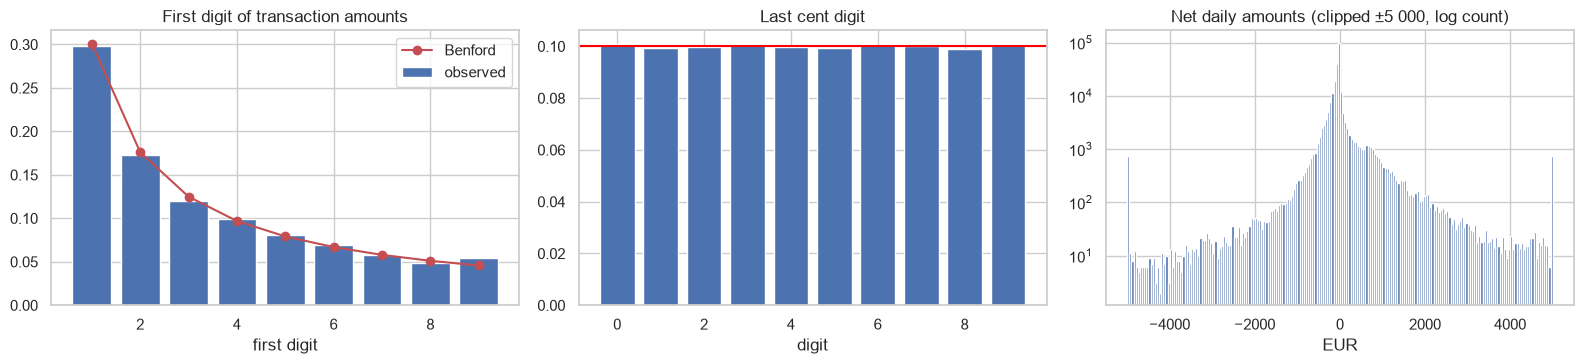

In [21]:
tx_ids = sample_accounts(bal.index, MAX_TEST_ACCOUNTS)
D = dB[bal.index.get_indexer(tx_ids)]
nz_mask = ~np.isnan(D) & (D != 0)
ai, ti = np.nonzero(nz_mask)
tx = pd.DataFrame({"ACCOUNT_ID": tx_ids.to_numpy()[ai], "date": cd[ti], "amount": np.round(D[nz_mask], 2)})
tx["month"] = tx.date.dt.to_period("M")
tx["day"] = tx.date.dt.day

cents = np.rint(np.abs(tx.amount.to_numpy()) * 100).astype(np.int64)
cents = cents[cents > 0]
n_digits = np.floor(np.log10(cents) + 1e-9).astype(np.int64)
first_digit = cents // 10 ** n_digits
benford = pd.DataFrame({"observed": np.bincount(first_digit, minlength=10)[1:] / len(first_digit),
                        "Benford": np.log10(1 + 1 / np.arange(1, 10))}, index=pd.Index(range(1, 10), name="first digit"))
benford_mad = float((benford.observed - benford.Benford).abs().mean())
last_digit = np.bincount(cents % 10, minlength=10) / len(cents)
chi_last = stats.chisquare(np.bincount(cents % 10, minlength=10))

forensics = pd.Series({
    "net daily amounts analysed": len(tx),
    "share inflows (> 0)": round((tx.amount > 0).mean(), 3),
    "Benford MAD (first digit; < 0.006 = close conformity)": round(benford_mad, 4),
    "last cent digit: chi-square p-value (uniform?)": round(chi_last.pvalue, 4),
    "share whole euros (expected 1% if cents random)": round(np.mean(cents % 100 == 0), 4),
    "share multiples of EUR 10 (expected 0.1%)": round(np.mean(cents % 1000 == 0), 4),
    "share multiples of EUR 20 (expected 0.05%)": round(np.mean(cents % 2000 == 0), 4),
})
display(forensics.to_frame("value"))
top_amounts = tx.amount.value_counts().head(20).rename("occurrences")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].bar(benford.index, benford.observed, label="observed"); axes[0].plot(benford.index, benford.Benford, "ro-", label="Benford")
axes[0].set(title="First digit of transaction amounts", xlabel="first digit"); axes[0].legend()
axes[1].bar(range(10), last_digit); axes[1].axhline(0.1, color="red"); axes[1].set(title="Last cent digit", xlabel="digit")
axes[2].hist(tx.amount.clip(-5000, 5000), bins=200); axes[2].set_yscale("log")
axes[2].set(title="Net daily amounts (clipped ±5 000, log count)", xlabel="EUR")
plt.tight_layout(); plt.show()
save_result(forensics.rename("value"), "D1_amount_forensics", "Forensic tests on net daily amounts: Benford, cents, round amounts")
save_result(benford, "D1_benford", "First-digit distribution of amounts vs Benford's law")
save_result(top_amounts, "D1_top_amounts", "Most frequent exact net daily amounts")

The amounts follow Benford's law closely and the cents are spread evenly, just as real amounts would be. There are no
round amounts beyond what chance predicts, so no cash withdrawals in multiples of €10 or €20. Whoever generated this
data did it carefully: there is no artificial shortcut to exploit, and we can treat it as real. The most frequent
exact amounts, on the other hand, repeat suspiciously often, and they are the subject of the next section.

## D2. Payments that come back

Rent, subscriptions and loan instalments show up as the same exact amount, in the same account, month after month. If
they also fall on the same date, we could place them in the forecast almost with certainty.

,value
"recurring (account, amount) pairs (>= 6 months)",1344.000
accounts with at least one recurring amount,398.000
share of transactions that are recurring,0.068
recurring pairs that are inflows,162.000
recurring pairs on a fixed day of month (std <= 2 days),275.000
median gap between occurrences (days),60.000
median std of the day of month,7.500


,,occurrences,months,first,last,day_of_month_median,day_of_month_std,gap_median,gap_std,fixed_date,direction
ACCOUNT_ID,amount,,,,,,,,,,
158,-20.06,149,33,2020-01-15,2022-12-27,16.0,7.9,4.5,10.2,False,outflow
133,-102.46,106,33,2020-01-02,2022-12-19,15.5,9.1,7.0,11.4,False,outflow
176,-20.84,95,27,2020-01-14,2022-12-13,16.0,8.6,5.0,21.4,False,outflow
230,-48.62,92,31,2020-01-20,2022-12-29,20.0,8.2,7.0,12.1,False,outflow
12,-20.68,72,29,2020-01-17,2022-12-28,17.0,7.2,7.0,18.0,False,outflow
323,-416.65,68,32,2020-01-13,2022-12-01,15.0,7.2,11.0,15.0,False,outflow
145,-39.80,65,29,2020-01-14,2022-11-22,16.0,8.1,10.5,17.8,False,outflow
409,-59.94,61,29,2020-01-09,2022-12-21,17.0,7.3,13.0,18.5,False,outflow
12,-10.34,61,23,2020-01-22,2022-11-24,17.0,7.5,8.0,29.7,False,outflow


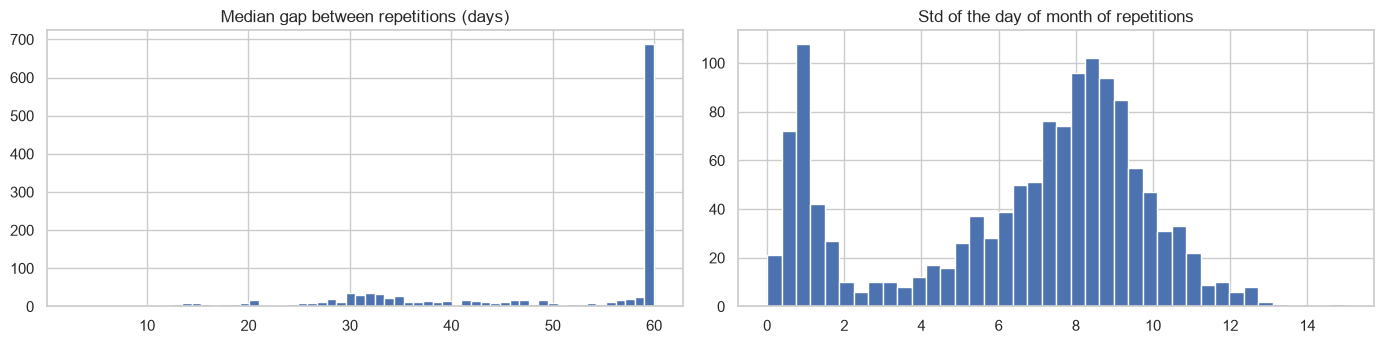

In [22]:
txs = tx[tx.amount.abs() >= 5].sort_values(["ACCOUNT_ID", "amount", "date"])
same = (txs.ACCOUNT_ID.values[1:] == txs.ACCOUNT_ID.values[:-1]) & (txs.amount.values[1:] == txs.amount.values[:-1])
gap_days = np.where(same, (txs.date.values[1:] - txs.date.values[:-1]) / np.timedelta64(1, "D"), np.nan)
txs["gap_days"] = np.r_[np.nan, gap_days]
rec = txs.groupby(["ACCOUNT_ID", "amount"]).agg(
    occurrences=("date", "size"), months=("month", "nunique"), first=("date", "min"), last=("date", "max"),
    day_of_month_median=("day", "median"), day_of_month_std=("day", "std"),
    gap_median=("gap_days", "median"), gap_std=("gap_days", "std"))
recurring = rec[rec.months >= 6].copy()
recurring["fixed_date"] = recurring.day_of_month_std <= 2
recurring["direction"] = np.where(recurring.index.get_level_values("amount") > 0, "inflow", "outflow")

is_rec = pd.MultiIndex.from_frame(txs[["ACCOUNT_ID", "amount"]]).isin(recurring.index)
rec_summary = pd.Series({
    "recurring (account, amount) pairs (>= 6 months)": len(recurring),
    "accounts with at least one recurring amount": recurring.index.get_level_values(0).nunique(),
    "share of transactions that are recurring": round(is_rec.mean(), 3),
    "recurring pairs that are inflows": int((recurring.direction == "inflow").sum()),
    "recurring pairs on a fixed day of month (std <= 2 days)": int(recurring.fixed_date.sum()),
    "median gap between occurrences (days)": recurring.gap_median.median(),
    "median std of the day of month": round(recurring.day_of_month_std.median(), 1),
})
display(rec_summary.to_frame("value"))
display(recurring.sort_values("occurrences", ascending=False).head(10).round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
axes[0].hist(recurring.gap_median.clip(0, 60), bins=60); axes[0].set(title="Median gap between repetitions (days)")
axes[1].hist(recurring.day_of_month_std.dropna(), bins=40); axes[1].set(title="Std of the day of month of repetitions")
plt.tight_layout(); plt.show()
save_result(rec_summary.rename("value"), "D2_recurring_summary", "Recurring transactions: counts and regularity")
save_result(recurring.reset_index(), "D2_recurring_amounts", "Every (account, amount) pair repeating in >= 6 months", index=False)

Most accounts have amounts that come back over many months, mostly outgoing ones. The majority behave like habits
rather than schedules: the same purchase, on any day of the month. About one in five of these recurring amounts,
however, falls on the same day every month, and those can be projected into the forecast window. Recurring amounts are
only a small share of all transactions, so they will refine the forecast of some accounts rather than explain the
balances as a whole.

## D3. Paydays

For each account and month we take the largest inflow and note its day. If an account is paid on a fixed day, that day
will dominate. We also check whether paydays follow the calendar (the 30th) or a business-day rule (the last business
day of the month), and what happens to the busy 8th when it falls on a weekend.

In [23]:
inflows = tx[tx.amount > 0]
top_in = inflows.loc[inflows.groupby(["ACCOUNT_ID", "month"]).amount.idxmax()].copy()
bdays = pd.bdate_range(bal.columns.min(), bal.columns.max() + pd.Timedelta(days=40))
bday_rank_from_end = pd.Series(
    pd.Series(bdays).groupby(pd.Series(bdays).dt.to_period("M")).rank(ascending=False).to_numpy(), index=bdays)
top_in["bdays_to_month_end"] = top_in.date.map(bday_rank_from_end)


def mode_share(s):
    return s.value_counts(normalize=True).iloc[0] if len(s) else np.nan


payday = top_in.groupby("ACCOUNT_ID").agg(
    payday_mode=("day", lambda s: s.mode().iloc[0]),
    calendar_day_concentration=("day", mode_share),
    business_day_concentration=("bdays_to_month_end", mode_share),
    months=("month", "size"))
payday["regular_payday"] = payday.calendar_day_concentration >= 0.5
display(pd.Series({
    "accounts analysed": len(payday),
    "accounts with a regular payday (same day in >= 50% of months)": int(payday.regular_payday.sum()),
    "median concentration on the modal calendar day": round(payday.calendar_day_concentration.median(), 3),
    "median concentration on the modal business-day-to-month-end": round(payday.business_day_concentration.median(), 3),
}).to_frame("value"))
display(top_in.day.value_counts(normalize=True).head(10).round(3).to_frame("share of accounts' largest monthly inflow"))

# Day 8: what happens when the 8th falls on a weekend?
li = cal["large_inflow"]
rows = []
for m in pd.period_range(cd.min(), cd.max(), freq="M"):
    d8 = pd.Timestamp(year=m.year, month=m.month, day=8)
    row = {"weekday of the 8th": weekday_names[d8.dayofweek]}
    for k in range(5, 12):
        dk = pd.Timestamp(year=m.year, month=m.month, day=k)
        row[f"day {k}"] = li.get(dk, np.nan)
    rows.append(row)
day8 = pd.DataFrame(rows).groupby("weekday of the 8th").mean().reindex(weekday_names).round(3)
display(day8)
save_result(payday, "D3_payday_per_account", "Per account: modal day of the largest monthly inflow and its concentration")
save_result(day8, "D3_day8_weekend_rule", "Share of accounts with a large inflow on days 5-11, by weekday of the 8th")

,value
accounts analysed,500.000
accounts with a regular payday (same day in >= 50% of months),109.000
median concentration on the modal calendar day,0.306
median concentration on the modal business-day-to-month-end,0.333


,share of accounts' largest monthly inflow
day,
8,0.119
30,0.076
28,0.072
29,0.061
31,0.046
25,0.039
27,0.036
23,0.036
1,0.034


,day 5,day 6,day 7,day 8,day 9,day 10,day 11
weekday of the 8th,,,,,,,
Mon,0.052,0.000,0.000,0.168,0.063,0.036,0.031
Tue,0.000,0.000,0.088,0.163,0.048,0.052,0.038
Wed,0.000,0.077,0.060,0.152,0.049,0.031,0.000
Thu,0.067,0.067,0.060,0.164,0.057,0.000,0.000
Fri,0.061,0.051,0.051,0.166,0.000,0.000,0.066
Sat,0.047,0.054,0.074,0.000,0.000,0.156,0.049
Sun,0.060,0.062,0.000,0.000,0.167,0.057,0.040


The 8th is the most common day for an account's largest inflow, followed by the 28th to the 30th. Account by account
the picture is looser: only about a fifth of the accounts are paid on the same day in most months. A business-day rule
does not describe paydays better than the plain calendar day.

The weekend table is the most useful result. When the 8th falls on a Saturday the money arrives on Monday the 10th,
and when it falls on a Sunday it arrives on Monday the 9th. The inflow is simply moved to the next business day. This
has a direct consequence for our forecast: 8 January 2023 is a Sunday, so those inflows should be expected on Monday
9 January.

## D4. Is there a floor?

An account with an authorised overdraft cannot go below its limit, so its balance should keep touching the same
minimum. If that happened, a forecast should never go below it. We count, for every account with negative balances,
how many separate times it came within 2% of its lowest value.

In [24]:
floor_rows = []
for acc in bal.index:
    s = bal.loc[acc].dropna()
    m = s.min()
    if m >= 0:
        continue
    near_min = (s <= m + 0.02 * abs(m)).astype(int)
    floor_rows.append({"ACCOUNT_ID": acc, "minimum": m, "days_near_minimum": int(near_min.sum()),
                       "episodes_near_minimum": int((near_min.diff() == 1).sum() + near_min.iloc[0]),
                       "minimum_is_round_100": abs(m) % 100 < 1})
floors = pd.DataFrame(floor_rows).set_index("ACCOUNT_ID")
display(pd.Series({
    "accounts with negative balances": len(floors),
    "accounts touching their minimum in >= 3 separate episodes": int((floors.episodes_near_minimum >= 3).sum()),
    "accounts whose minimum is a round multiple of EUR 100": int(floors.minimum_is_round_100.sum()),
}).to_frame("value"))
save_result(floors, "D4_overdraft_floors", "Per account with negatives: minimum, days and episodes near the minimum")

,value
accounts with negative balances,358
accounts touching their minimum in >= 3 separate episodes,23
accounts whose minimum is a round multiple of EUR 100,3


Very few accounts return repeatedly to their minimum, and almost no minimum is a round number such as −€500. We find
no sign of hard credit limits, so our forecasts do not need a floor.

## D5. Are accounts linked?

Section 14 found weak correlations, but two specific links could still exist. One is a transfer: money leaving one
account and arriving, with exactly the same amount, in another on the same day. The other is a duplicated account. To
know whether matches are real or coincidence, we compare them with the matches we get after shuffling the dates at
random.

In [25]:
big_tx = tx[tx.amount.abs() >= 50][["ACCOUNT_ID", "date", "amount"]]


def count_matches(t):
    m = t.merge(t.assign(amount=-t.amount), on=["date", "amount"], suffixes=("_out", "_in"))
    return m[(m.ACCOUNT_ID_out != m.ACCOUNT_ID_in) & (m.amount < 0)]


matches = count_matches(big_tx)
shuffled = [len(count_matches(big_tx.assign(date=rng.permutation(big_tx.date.values)))) for _ in range(5)]

dup_ids = sample_accounts(bal.index, MAX_CORR_ACCOUNTS)
Zc = np.nan_to_num(dB[bal.index.get_indexer(dup_ids)])
dup_rows = []
for lag in range(4):
    A, Bm = Zc[:, lag:], Zc[:, :Zc.shape[1] - lag]
    same_moves = np.zeros((len(dup_ids), len(dup_ids)), dtype=np.int32)
    for i in range(len(dup_ids)):
        same_moves[i] = ((A[i] == Bm) & (A[i] != 0)).sum(1)
    np.fill_diagonal(same_moves, 0)
    i, j = np.unravel_index(same_moves.argmax(), same_moves.shape)
    dup_rows.append({"lag (days)": lag, "max identical non-zero changes": int(same_moves.max()),
                     "account": dup_ids[i], "other account": dup_ids[j]})
links = pd.Series({
    "candidate transfers (same day, opposite exact amount >= EUR 50)": len(matches),
    "expected by chance (mean of 5 date shuffles)": float(np.mean(shuffled)),
    "account pairs with >= 3 transfers": int((matches.groupby(["ACCOUNT_ID_out", "ACCOUNT_ID_in"]).size() >= 3).sum()),
})
display(links.to_frame("value"))
display(pd.DataFrame(dup_rows))
save_result(links.rename("value"), "D5_transfers", "Transfer detection vs permutation baseline")
save_result(pd.DataFrame(dup_rows), "D5_duplicates", "Max identical non-zero changes between two different accounts, by lag", index=False)

,value
"candidate transfers (same day, opposite exact amount >= EUR 50)",87.0
expected by chance (mean of 5 date shuffles),93.2
account pairs with >= 3 transfers,0.0


,lag (days),max identical non-zero changes,account,other account
0,0,2,89,396
1,1,2,68,97
2,2,1,1,458
3,3,2,118,228


We find exactly as many "transfers" as chance produces, no pair of accounts that exchanges money repeatedly, and no
two accounts sharing more than a couple of identical moves. The accounts are independent of each other, which
confirms what section 14 suggested.

## D6. The exact cycles

In section 9 we told the decomposition to look for cycles of 7 and 30 days. The periodogram lets the data speak for
itself: it splits the variance of the daily changes across all possible frequencies. We average it across accounts to
see which periods stand out.

,period (days),share of variance (%)
0,30.30,1.65
1,15.15,1.43
2,10.10,0.92
3,7.63,0.61
4,6.10,0.52
5,7.58,0.52
6,3.26,0.52
7,6.99,0.52
8,10.20,0.52
9,2.94,0.51


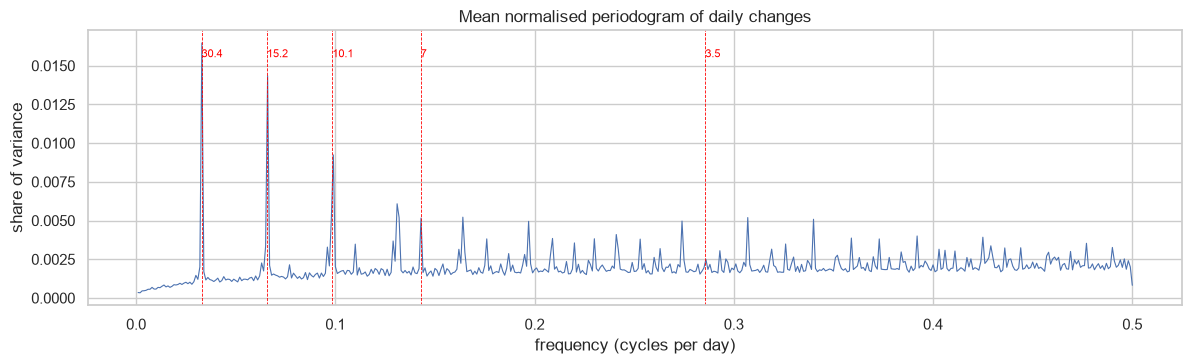

In [26]:
spec_ids = sample_accounts(bal.index, MAX_TEST_ACCOUNTS)
N_SPEC = 1000
spectra, spec_entropy = [], {}
for acc in spec_ids:
    x = np.diff(bal.loc[acc].dropna().to_numpy())[-N_SPEC:]
    if len(x) < N_SPEC or np.std(x) == 0:
        continue
    freqs, power = periodogram(x - x.mean())
    p = power[1:] / power[1:].sum()
    spectra.append(p)
    spec_entropy[acc] = float(-(p * np.log(p + 1e-300)).sum() / np.log(len(p)))
mean_spec = pd.Series(np.mean(spectra, 0), index=1 / freqs[1:])
top_periods = mean_spec.sort_values(ascending=False).head(10)
display(pd.DataFrame({"period (days)": top_periods.index.round(2), "share of variance (%)": (100 * top_periods.values).round(2)}))

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(freqs[1:], mean_spec.values, lw=0.8)
for per_, lab in [(30.44, "30.4"), (15.22, "15.2"), (10.15, "10.1"), (7, "7"), (3.5, "3.5")]:
    ax.axvline(1 / per_, color="red", ls="--", lw=0.6); ax.text(1 / per_, ax.get_ylim()[1] * 0.9, lab, color="red", fontsize=8)
ax.set(title="Mean normalised periodogram of daily changes", xlabel="frequency (cycles per day)", ylabel="share of variance")
plt.tight_layout(); plt.show()
save_result(pd.DataFrame({"period_days": mean_spec.index, "share_of_variance": mean_spec.values}),
            "D6_mean_periodogram", "Mean normalised periodogram of daily changes across accounts", index=False)

The strongest cycle lasts about 30.4 days, the average length of a month, and it is followed by cycles of about 15.2
and 10.1 days. Those are not new rhythms but echoes of the monthly one: a saw-tooth (sudden rise, slow decline) is
not a smooth wave, and it takes several harmonics to draw it. The weekly cycle is present but weaker.

For the models this means describing the month with several Fourier terms of period 30.44, or with day-of-month
effects, rather than with a single seasonal lag of 30 days.

## D7. When did each account last change?

We saw that accounts jump to new levels and stay there. If an account changed level two months ago, its older history
describes a different situation. We detect these change points by comparing the median of the 30 days before and after
each date, and flag a change when the difference is larger than half the account's typical balance and larger than
€100.

,change_points,days_since_last_change_point
count,500.0,460.0
mean,10.9,140.7
std,7.2,184.0
min,0.0,29.0
25%,5.0,34.0
50%,11.0,57.5
75%,17.0,158.0
max,27.0,1031.0


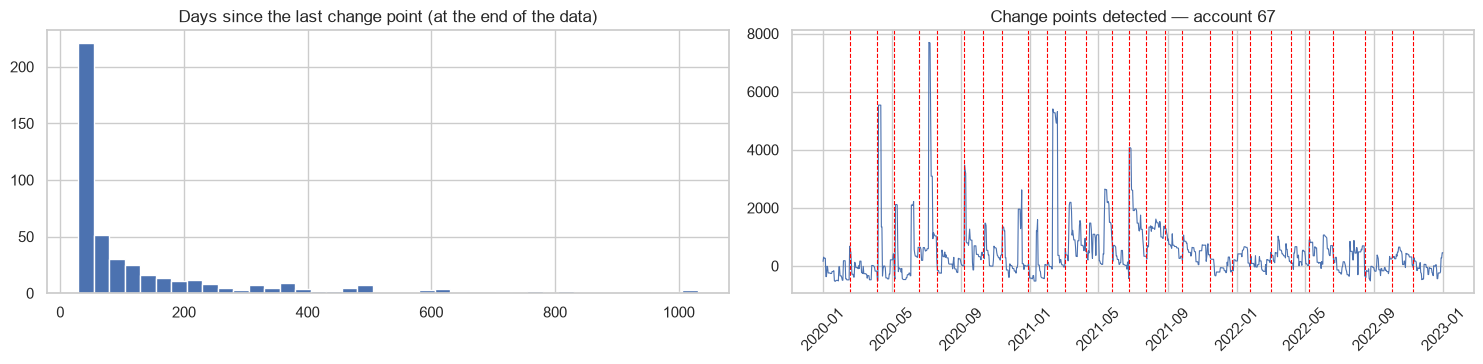

In [27]:
CP_WINDOW = 30


def level_change_points(s, w=CP_WINDOW):
    x = s.dropna()
    v = x.to_numpy()
    n = len(v)
    if n < 3 * w:
        return []
    before = pd.Series(v).rolling(w).median().to_numpy()                 # median of v[t-w+1 .. t]
    after = pd.Series(v[::-1]).rolling(w).median().to_numpy()[::-1]      # median of v[t .. t+w-1]
    shift = np.full(n, np.nan)
    shift[w - 1:n - w] = after[w:n - w + 1] - before[w - 1:n - w]
    threshold = max(0.5 * np.median(np.abs(v)), 100.0)
    candidates = np.flatnonzero(np.abs(np.nan_to_num(shift)) > threshold)
    points = []
    for t in candidates[np.argsort(-np.abs(shift[candidates]))]:            # strongest first, at least w apart
        if all(abs(t - p) >= w for p in points):
            points.append(t)
    return sorted(x.index[p + 1] for p in points)


cp_ids = sample_accounts(bal.index, MAX_TEST_ACCOUNTS)
cps = {acc: level_change_points(bal.loc[acc]) for acc in cp_ids}
end = bal.columns.max()
cp_table = pd.DataFrame({
    "change_points": {a: len(v) for a, v in cps.items()},
    "last_change_point": {a: (v[-1] if v else pd.NaT) for a, v in cps.items()},
})
cp_table["days_since_last_change_point"] = (end - cp_table.last_change_point).dt.days
display(cp_table[["change_points", "days_since_last_change_point"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
axes[0].hist(cp_table.days_since_last_change_point.dropna(), bins=40)
axes[0].set(title="Days since the last change point (at the end of the data)")
example = cp_table.change_points.idxmax()
axes[1].plot(bal.columns, bal.loc[example], lw=0.8)
for p in cps[example]:
    axes[1].axvline(p, color="red", lw=0.8, ls="--")
axes[1].set_title(f"Change points detected — account {example}"); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
save_result(cp_table, "D7_change_points_per_account", "Per account: number of level change points and the last one")

The exact counts depend on the window and the threshold we chose, so we read them as indicative. Most accounts change
level several times over three years, and for half of them the last change happened less than two months before the
end of the data. Estimating a level from the full three years would mix regimes; the models should focus on the recent
past, or at least give it more weight.

## D8. January

We will forecast the 30 days that follow 31 December. We have already lived through that period twice, in 2021 and
2022, so we can look at how balances moved after New Year's Eve and compare it with what happens after an ordinary
month end.

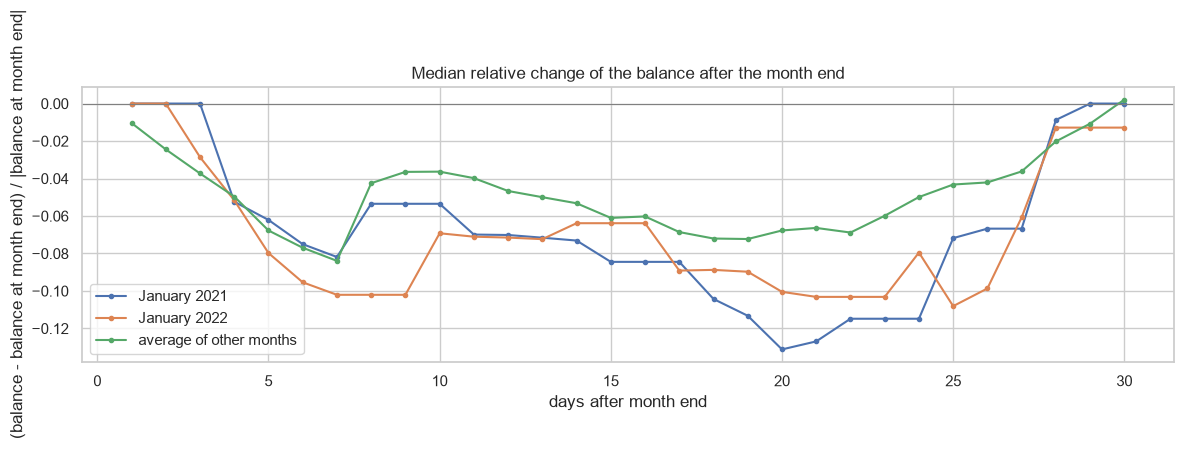

,January 2021,January 2022,average of other months
days after month end,,,
5,-0.062,-0.080,-0.068
10,-0.053,-0.069,-0.036
15,-0.084,-0.064,-0.061
20,-0.131,-0.100,-0.068
25,-0.072,-0.108,-0.043
30,0.000,-0.013,0.002


In [28]:
def relative_path(start):
    base = bal[start]
    window = bal.loc[:, start + pd.Timedelta(days=1): start + pd.Timedelta(days=HORIZON)]
    rel_path = window.sub(base, axis=0).div(base.abs().clip(lower=NEAR_ZERO), axis=0)
    return rel_path.median(axis=0).to_numpy()


paths = {}
for y in sorted(set(bal.columns.year))[1:]:
    paths[f"January {y}"] = relative_path(pd.Timestamp(f"{y - 1}-12-31"))
month_ends = [d for d in bal.columns[bal.columns.is_month_end] if d.month != 12 and d + pd.Timedelta(days=HORIZON) <= end]
paths["average of other months"] = np.mean([relative_path(d) for d in month_ends], axis=0)
paths = pd.DataFrame(paths, index=pd.Index(range(1, HORIZON + 1), name="days after month end"))

paths.plot(figsize=(12, 3.8), marker=".", title="Median relative change of the balance after the month end")
plt.axhline(0, color="grey", lw=0.8); plt.ylabel("(balance - balance at month end) / |balance at month end|")
plt.tight_layout(); plt.show()
display(paths.iloc[[4, 9, 14, 19, 24, 29]].round(3))
save_result(paths, "D8_january_paths", "Median relative balance path after Dec 31 (each January) vs after other month ends")

After 31 December the typical balance goes down during the first weeks of January and recovers at the end of the
month, when the next salary arrives. It is the familiar saw-tooth, but the January dip is at least as deep as in an
ordinary month, probably because of post-Christmas spending. A forecast that simply repeats the 31 December balance
will be too high for most of the month. The forecast needs to follow the within-month profile, and the January folds
of our validation are the right place to calibrate it.

## D9. How we will keep score

Before asking how good a forecast can be, we fix the scoring rules used from now on. The decision metric is the
official MAPE, computed over all accounts and days, leaving out the few exact zeros where it is undefined. Next to it
we report the median MAPE across accounts and the MAPE on balances of at least €100, so that we can always tell
whether a bad score comes from the typical account or from the near-zero ones. We also define the validation folds
here: four recent 30-day windows at the end of 2022 and January 2022, each forecast using only the data before it.

In [29]:
def mape_official(actual, forecast):
    """MAPE as in the brief, pooled over all points; undefined points (actual = 0 or missing) are excluded."""
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    ok = np.isfinite(a) & np.isfinite(f) & (a != 0)
    return 100 * np.mean(np.abs((a[ok] - f[ok]) / a[ok]))


def mape_per_account(actual, forecast, min_abs=0.0):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    ok = np.isfinite(a) & np.isfinite(f) & (np.abs(a) > min_abs)
    ape = np.where(ok, np.abs((a - f) / np.where(ok, a, 1)), np.nan)
    return 100 * np.nanmean(ape, axis=1)


def evaluate(actual, forecast, train=None):
    """Official MAPE plus the two explanatory MAPE variants for an (accounts x horizon) forecast."""
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    f = np.broadcast_to(f, a.shape)
    ok = np.isfinite(a) & np.isfinite(f) & (np.abs(a) >= NEAR_ZERO)
    return {
        "MAPE (official)": mape_official(a, f),
        "median per-account MAPE": np.nanmedian(mape_per_account(a, f)),
        f"MAPE |actual|>={NEAR_ZERO:.0f}": 100 * np.mean(np.abs((a[ok] - f[ok]) / a[ok])),
    }


METRICS = ["MAPE (official)", "median per-account MAPE", f"MAPE |actual|>={NEAR_ZERO:.0f}"]

# Validation folds (used in D10 and §17): train up to the origin, forecast the next HORIZON days
last_day = bal.columns.max()
origins = [pd.Timestamp("2021-12-31")] + [last_day - pd.Timedelta(days=HORIZON * k) for k in (4, 3, 2, 1)]


def split(data, origin):
    train = data.loc[:, :origin]
    test = data.loc[:, origin + pd.Timedelta(days=1): origin + pd.Timedelta(days=HORIZON)]
    return train, test

## D10. How good could a forecast be?

An oracle is a forecast that is allowed to peek at the future. It is not a model, only a yardstick: it tells us how
much of the error could disappear in the best case. We use the simplest oracle, one constant value per account for the
whole window, chosen to minimise MAPE. That value is a weighted median of the true balances in which each balance
counts in inverse proportion to its size. Comparing it with our simple forecasts shows how much of the error comes
from choosing the wrong level and how much from missing the movement inside the month.

In [30]:
def mape_optimal_constant(A):
    """Per row: the constant c minimising sum |a - c| / |a| (weighted median, weights 1/|a|)."""
    out = np.full(A.shape[0], np.nan)
    for i, row in enumerate(A):
        a = row[np.isfinite(row) & (row != 0)]
        if len(a) == 0:
            continue
        o = np.argsort(a); w = 1 / np.abs(a[o]); cw = np.cumsum(w)
        out[i] = a[o][np.searchsorted(cw, cw[-1] / 2)]
    return out


oracle_rows = []
for origin in origins:
    train, test = split(bal, origin)
    A = test.to_numpy(); T = train.to_numpy()
    fold = (origin + pd.Timedelta(days=1)).date()
    candidates = {
        "naive (last value)": T[:, -1:],
        "median of last 30 days": np.nanmedian(T[:, -30:], 1, keepdims=True),
        "ORACLE: best constant per account": mape_optimal_constant(A)[:, None],
        "ORACLE: actual mean of the window": np.nanmean(A, 1, keepdims=True),
    }
    for name, fc in candidates.items():
        oracle_rows.append({"fold (test start)": fold, "forecast": name, **evaluate(A, fc, T)})
oracle = pd.DataFrame(oracle_rows)
oracle_summary = oracle.groupby("forecast")[METRICS].mean().sort_values("MAPE (official)")
display(oracle_summary.round(2))
save_result(oracle, "D10_oracle_by_fold", "Baselines vs oracle constant forecasts, all metrics per fold", index=False)
save_result(oracle_summary, "D10_oracle_summary", "Baselines vs oracle constant forecasts, averaged over folds")

,MAPE (official),median per-account MAPE,MAPE |actual|>=100
forecast,,,
ORACLE: best constant per account,43.59,37.86,39.91
ORACLE: actual mean of the window,1236.23,58.32,53.56
naive (last value),1302.74,68.83,88.70
median of last 30 days,3032.63,66.54,71.46


The gap is enormous. A constant at the right level reaches an official MAPE more than twenty times lower than the
simple forecasts. In other words, most of the official error is not about the daily ups and downs: it is about
choosing the wrong level for the accounts that sit near zero. The oracle constant also beats the true average of the
window by far, which confirms the asymmetry we found in section 5: MAPE rewards forecasts that lean towards zero.

This is the most important lesson for Sprint 2. The largest gains will come from getting the level right for the
near-zero and sign-changing accounts, and from pulling forecasts towards zero when we are unsure, more than from
modelling the within-month movement in great detail.

## D11. Which accounts are hard to forecast, and why?

For every account we compute the error of the simplest forecast, carrying the last balance forward, and relate it to
the account's characteristics: how often it moves, how close to zero it lives, how variable it is, and its spectral
entropy, a measure of how close its daily changes are to pure noise.

In [31]:
per_acc_err = []
for origin in origins:
    train, test = split(bal, origin)
    per_acc_err.append(mape_per_account(test.to_numpy(), train.to_numpy()[:, -1:]))
naive_mape_acc = pd.Series(np.nanmean(per_acc_err, axis=0), index=bal.index, name="naive_MAPE")
drivers = pd.DataFrame({
    "naive_MAPE": naive_mape_acc,
    "spectral_entropy": pd.Series(spec_entropy),
    "activity": feat.activity,
    "share_near_zero": feat.share_near_zero,
    "share_negative": feat.share_negative,
    "cv": feat.cv,
})
driver_corr = drivers.corr(method="spearman")["naive_MAPE"].drop("naive_MAPE").rename("Spearman rho with naive MAPE")
display(driver_corr.round(3).to_frame())
display(drivers.groupby(feat.segment).naive_MAPE.median().round(1).to_frame("median naive MAPE by segment"))
save_result(drivers, "D11_predictability_per_account", "Per account: naive MAPE and candidate drivers (entropy, activity, near-zero, ...)")
save_result(driver_corr, "D11_error_drivers", "Spearman correlation of account characteristics with naive MAPE")

,Spearman rho with naive MAPE
spectral_entropy,-0.166
activity,0.169
share_near_zero,0.765
share_negative,0.663
cv,0.732


,median naive MAPE by segment
segment,
dormant,12380.1
near-zero / overdraft,327.7
stable positive,11.9
volatile positive,131.1


The error follows closely how near zero an account lives and how much it varies relative to its level. Whether its
daily changes look like noise matters much less. The groups from section 15 tell the same story: stable positive
accounts are easy, while accounts that live near zero, the dormant ones included, carry the highest errors.

## D12. The risk of crossing zero

If the near-zero accounts are the problem, we would like to spot them in advance. We measure, over many past moments,
how often a balance crossed zero in the following 30 days, depending on how far it was from zero, measured in units of
its own recent volatility.

In [32]:
zc_rows = []
for o in range(400, B.shape[1] - HORIZON, HORIZON):
    last_b = B[:, o]
    window = B[:, o + 1:o + 1 + HORIZON]
    vol = np.nanstd(B[:, o - 30:o], axis=1)
    crosses = ((np.nanmin(window, 1) < 0) & (np.nanmax(window, 1) > 0)) | \
              ((np.nanmin(window, 1) < 0) & (last_b > 0)) | ((np.nanmax(window, 1) > 0) & (last_b < 0))
    zc_rows.append(pd.DataFrame({"distance_in_vols": np.abs(last_b) / np.where(vol > 0, vol, np.nan), "crosses": crosses}))
zc = pd.concat(zc_rows).dropna()
zc["distance band"] = pd.cut(zc.distance_in_vols, [0, 0.5, 1, 2, 3, 5, np.inf])
zero_cross = zc.groupby("distance band", observed=True).agg(observations=("crosses", "size"), p_cross=("crosses", "mean"))
display(zero_cross.round(3))
save_result(zero_cross.rename(index=str), "D12_zero_crossing_risk", "P(balance crosses zero within 30 days) by |balance| / recent volatility")

,observations,p_cross
distance band,,
"(0.0, 0.5]",1852,0.735
"(0.5, 1.0]",1141,0.672
"(1.0, 2.0]",1765,0.520
"(2.0, 3.0]",1537,0.375
"(3.0, 5.0]",1559,0.213
"(5.0, inf]",3625,0.038


The relationship is steep. An account within one volatility of zero crosses it in the next month most of the time,
while one more than five volatilities away almost never does. This gives Sprint 2 a simple warning sign: a low ratio
of balance to volatility marks the accounts where MAPE can explode and where a dedicated strategy is worth the
effort.

## D13. Long memory?

The Hurst exponent measures memory in a different way from the autocorrelation. A value of 0.5 means no memory, above
0.5 movements tend to continue, below 0.5 they tend to reverse. We compute it on the daily changes of every account.

,hurst_changes
count,500.000
mean,0.380
std,0.073
min,0.199
10%,0.291
50%,0.373
90%,0.476
max,0.631


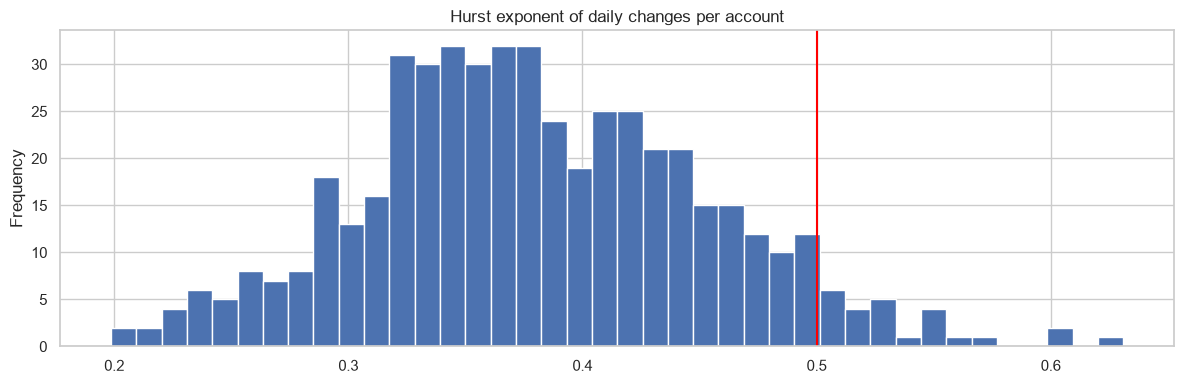

In [33]:
def hurst_rs(x, windows=(16, 32, 64, 128, 256)):
    x = x[np.isfinite(x)]
    rs = []
    for n in windows:
        k = len(x) // n
        seg = x[:k * n].reshape(k, n)
        y = np.cumsum(seg - seg.mean(1, keepdims=True), axis=1)
        R, S = y.max(1) - y.min(1), seg.std(1)
        rs.append(np.mean(R[S > 0] / S[S > 0]) if np.any(S > 0) else np.nan)
    return np.polyfit(np.log(windows), np.log(rs), 1)[0] if np.all(np.isfinite(rs)) else np.nan


hurst = pd.Series({acc: hurst_rs(np.diff(bal.loc[acc].dropna().to_numpy())) for acc in spec_ids}, name="hurst_changes")
display(hurst.describe(percentiles=[0.1, 0.5, 0.9]).round(3).to_frame())
hurst.plot.hist(bins=40, title="Hurst exponent of daily changes per account"); plt.axvline(0.5, color="red")
plt.tight_layout(); plt.show()
save_result(hurst, "D13_hurst_per_account", "Per account: Hurst exponent (R/S) of daily changes")

Almost every account has a value below 0.5. Movements tend to reverse: money that comes in is soon spent. This is the
saw-tooth again, seen from another angle, and it matches the slight negative autocorrelation of section 11. There is
no long memory, so long-memory models such as ARFIMA are not needed.

## D14. A map of all the accounts

So far we have described the accounts one property at a time. Forecasting researchers often go one step further:
they compute a set of features for every series (how persistent it is, how strong its cycles are, how often it
crosses zero, how lumpy its variance is) and then place all series on a single map. Accounts that sit close together
on the map behave alike and will probably need the same kind of model. We compute eighteen such features, convert
them to comparable scores, reduce them to two dimensions with a principal component analysis, and let a clustering
algorithm tell us how many natural groups there are.

,explained variance
PC1,0.393
PC2,0.176
PC3,0.101
PC4,0.082
PC5,0.056


,PC1,PC2
crossing_points,-0.31,0.01
log_cv,-0.27,-0.14
zero_crossings_per_year,-0.26,-0.03
lumpiness,-0.26,-0.34
share_near_zero,-0.25,-0.04
share_negative,-0.23,-0.02
acf10_diff,-0.21,-0.13
strength_weekly (7),-0.20,0.24
longest_flat_spell,-0.07,-0.06
strength_monthly (30),-0.05,0.50


,silhouette
2,0.233
3,0.182
4,0.160
5,0.133
6,0.141
7,0.137
8,0.129


cluster,0,1
acf1_level,0.98,0.86
acf1_diff,-0.01,-0.07
acf10_diff,0.02,0.04
stability,0.85,0.38
lumpiness,0.07,0.47
crossing_points,0.02,0.07
zero_crossings_per_year,0.00,18.98
longest_flat_spell,11.00,13.00
kurtosis_changes,112.83,37.25
strength_trend,0.94,0.64


segment,dormant,near-zero / overdraft,stable positive,volatile positive
cluster,,,,
0,0,17,125,87
1,1,178,13,79


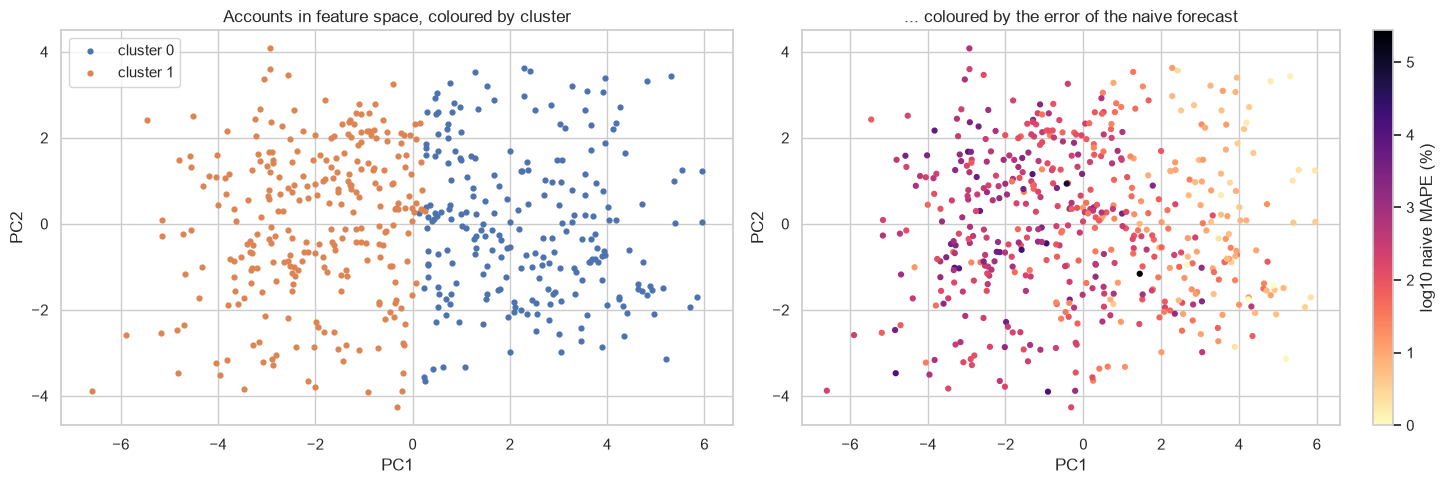

In [34]:
def series_features(s):
    """Feature vector describing one account (in the spirit of Hyndman's tsfeatures)."""
    x = s.dropna().to_numpy()
    d = np.diff(x)
    n = len(x)
    sd = x.std()
    z = (x - x.mean()) / sd if sd > 0 else np.zeros_like(x)
    k = n // 30
    blocks = z[-k * 30:].reshape(k, 30)
    unchanged = np.r_[False, d == 0]
    run_ends = np.flatnonzero(np.diff(np.r_[0, unchanged.astype(int), 0]))
    longest_flat = int((run_ends[1::2] - run_ends[::2]).max()) if len(run_ends) else 0
    above = x > np.median(x)
    return {
        "acf1_level": acf(x, nlags=1)[1] if sd > 0 else np.nan,
        "acf1_diff": acf(d, nlags=1)[1] if d.std() > 0 else np.nan,
        "acf10_diff": float(np.sum(acf(d, nlags=10)[1:] ** 2)) if d.std() > 0 else np.nan,
        "stability": float(blocks.mean(1).var()),
        "lumpiness": float(blocks.var(1).var()),
        "crossing_points": float(np.mean(above[1:] != above[:-1])),
        "zero_crossings_per_year": float(np.sum(np.sign(x[1:]) != np.sign(x[:-1])) / (n / 365)),
        "longest_flat_spell": longest_flat,
        "kurtosis_changes": float(stats.kurtosis(d)),
    }


ts_feat = pd.DataFrame({acc: series_features(bal.loc[acc]) for acc in bal.index}).T
ts_feat = ts_feat.join(strengths.add_prefix("strength_")).join(pd.Series(spec_entropy, name="spectral_entropy")) \
                 .join(hurst).join(feat[["activity", "share_near_zero", "share_negative", "cv"]])
ts_feat["log_cv"] = np.log10(ts_feat.pop("cv").clip(lower=1e-3))

# Rank-based normal scores make the features comparable and robust to extreme values
filled = ts_feat.fillna(ts_feat.median())
scores = filled.rank(pct=True).sub(0.5 / len(filled)).apply(stats.norm.ppf)
pca = PCA(n_components=5, random_state=RANDOM_STATE).fit(scores)
pcs = pd.DataFrame(pca.transform(scores)[:, :2], index=scores.index, columns=["PC1", "PC2"])
loadings = pd.DataFrame(pca.components_[:2].T, index=scores.columns, columns=["PC1", "PC2"])
explained = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i}" for i in range(1, 6)])

sil = {}
for k_ in range(2, 9):
    sil[k_] = silhouette_score(scores, KMeans(n_clusters=k_, n_init=10, random_state=RANDOM_STATE).fit_predict(scores))
best_k = max(sil, key=sil.get)
clusters = pd.Series(KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit_predict(scores),
                     index=scores.index, name="cluster")

display(explained.round(3).to_frame("explained variance"))
display(loadings.round(2).sort_values("PC1"))
display(pd.Series(sil).round(3).to_frame("silhouette"))
cluster_profile = ts_feat.groupby(clusters).median().T
cluster_profile.loc["accounts"] = clusters.value_counts().sort_index()
cluster_profile.loc["median naive MAPE"] = naive_mape_acc.groupby(clusters).median()
display(cluster_profile.round(2))
display(pd.crosstab(clusters, feat.segment))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for c in sorted(clusters.unique()):
    m_ = clusters == c
    axes[0].scatter(pcs.PC1[m_], pcs.PC2[m_], s=12, label=f"cluster {c}")
axes[0].legend(); axes[0].set(title="Accounts in feature space, coloured by cluster", xlabel="PC1", ylabel="PC2")
sc = axes[1].scatter(pcs.PC1, pcs.PC2, s=12, c=np.log10(naive_mape_acc.reindex(pcs.index).clip(lower=1)), cmap="magma_r")
plt.colorbar(sc, ax=axes[1], label="log10 naive MAPE (%)")
axes[1].set(title="... coloured by the error of the naive forecast", xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.show()
save_result(ts_feat.join(pcs).join(clusters), "D14_feature_space_per_account", "Per account: time-series features, PCA coordinates and cluster")
save_result(loadings, "D14_pca_loadings", "PCA loadings of the time-series features (PC1, PC2)")
save_result(cluster_profile, "D14_cluster_profiles", "Median features, size and naive MAPE of each cluster")

The map has one dominant direction. The first component, which carries about 40% of the information, runs from
accounts that are persistent, stable and far from zero to accounts that cross their median and zero often, vary a lot
relative to their level and spend much time near zero. The second component separates accounts with a strong monthly
cycle from accounts whose changes look like noise.

The clustering agrees with this reading. The best split has only two groups, and the separation is modest, which
tells us accounts form a continuum rather than tidy families. Still, the two groups are very different where it
matters: about 230 positive, stable accounts that the naive forecast already handles with a median error near 26%,
and about 270 accounts that live around zero, cross it almost twenty times a year and carry a median error ten times
higher. The rule-based segments of section 15 fall almost entirely on one side or the other. For Sprint 2 this is a
clear instruction: the main dividing line between accounts is their distance from zero, and it deserves its own
model strategy.

## D15. How often does money move?

Demand forecasters classify series by two numbers: how many periods pass, on average, between two non-zero values
(ADI) and how variable those non-zero values are (CV²). Syntetos and Boylan drew a grid with these two numbers that
separates smooth series from erratic, intermittent and lumpy ones, and each quadrant has its preferred methods. We
apply it to each account's inflows and outflows separately, on business days.

outflows,erratic,intermittent,lumpy,All
inflows,,,,
intermittent,2,0,79,81
lumpy,28,1,390,419
All,30,1,469,500


,inflows,outflows
ADI,9.07,1.90
CV2,1.44,3.08


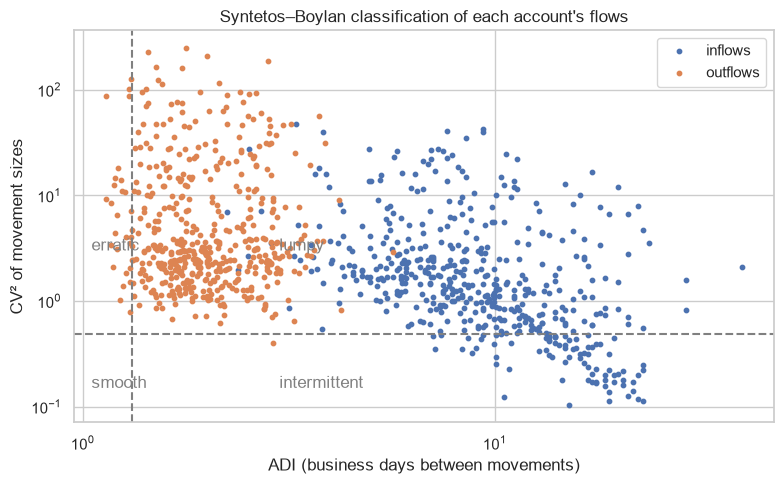

In [35]:
ADI_CUT, CV2_CUT = 1.32, 0.49
business_mask = np.array([(d.dayofweek < 5) and (d not in pt_holidays) for d in cd])


def syntetos_boylan(flows):
    """flows: accounts x business days, non-negative. Returns ADI, CV^2 and category per account."""
    occurs = flows > 0
    n_obs = np.sum(~np.isnan(flows), 1)
    n_occ = np.sum(occurs, 1)
    adi = n_obs / np.maximum(n_occ, 1)
    sizes = np.where(occurs, flows, np.nan)
    cv2 = (np.nanstd(sizes, 1) / np.nanmean(sizes, 1)) ** 2
    cat = np.select([(adi < ADI_CUT) & (cv2 < CV2_CUT), (adi < ADI_CUT), (cv2 < CV2_CUT)],
                    ["smooth", "erratic", "intermittent"], default="lumpy")
    return pd.DataFrame({"ADI": adi, "CV2": cv2, "category": np.where(n_occ < 2, "too few", cat)}, index=bal.index)


flows_b = dB[:, business_mask]
sb_in = syntetos_boylan(np.where(np.isnan(flows_b), np.nan, np.clip(flows_b, 0, None)))
sb_out = syntetos_boylan(np.where(np.isnan(flows_b), np.nan, np.clip(-flows_b, 0, None)))
sb_table = pd.crosstab(sb_in.category.rename("inflows"), sb_out.category.rename("outflows"), margins=True)
display(sb_table)
display(pd.DataFrame({"inflows": sb_in[["ADI", "CV2"]].median(), "outflows": sb_out[["ADI", "CV2"]].median()}).round(2))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sb_in.ADI, sb_in.CV2, s=10, label="inflows"); ax.scatter(sb_out.ADI, sb_out.CV2, s=10, label="outflows")
ax.axvline(ADI_CUT, color="grey", ls="--"); ax.axhline(CV2_CUT, color="grey", ls="--")
ax.set(xscale="log", yscale="log", xlabel="ADI (business days between movements)", ylabel="CV² of movement sizes",
       title="Syntetos–Boylan classification of each account's flows")
for txt, (xx, yy) in {"smooth": (1.05, 0.15), "erratic": (1.05, 3), "intermittent": (3, 0.15), "lumpy": (3, 3)}.items():
    ax.text(xx, yy, txt, color="grey")
ax.legend(); plt.tight_layout(); plt.show()
save_result(sb_in.add_prefix("inflow_").join(sb_out.add_prefix("outflow_")), "D15_syntetos_boylan_per_account",
            "Per account: ADI, CV2 and demand-pattern category of inflows and outflows")
save_result(sb_table, "D15_syntetos_boylan_table", "Accounts by inflow category x outflow category")

Almost every account falls in the lumpy quadrant, for both directions of money. Inflows arrive on average every nine
business days and their size varies a lot; outflows are more frequent, roughly every two business days, but their
sizes vary even more. Nothing about these flows is smooth.

This is useful for choosing what to forecast. Predicting each day's movement is close to hopeless when movements are
this lumpy, which is why forecasting the level of the balance, rather than the flows that build it, is the sensible
choice. If we do want to model flows, for example the payday inflow, the methods designed for intermittent demand
(Croston and its successors) are the natural candidates.

## D16. A break, not a random walk?

In section 10 the ADF and KPSS tests disagreed for about half of the accounts, and we suspected the level shifts. The
Zivot–Andrews test lets us check this: it is a unit-root test that allows the series to have one break in its level
at a date it chooses itself. If accounts that looked non-stationary become stationary once a single break is allowed,
then their apparent wandering is really a jump between two stable levels.

,% rejecting a unit root once a break is allowed,accounts
levels_class,,
conflicting: difference-stationary / level shifts,87.9,239
inconclusive,28.6,7
stationary (both agree),95.3,107
unit root (both agree),59.9,147


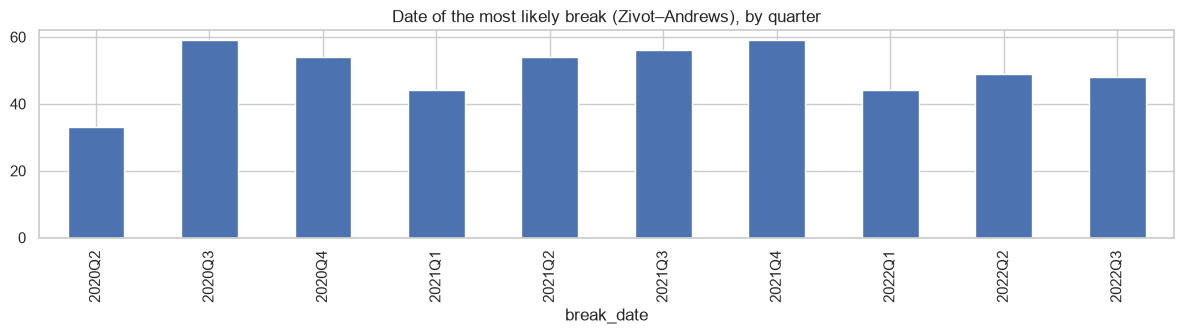

In [36]:
za_rows = {}
for acc in test_ids:
    x = bal.loc[acc].dropna()
    try:
        stat_, p_, _, _, bp = zivot_andrews(x.to_numpy(), trim=0.15, maxlag=7, regression="c", autolag=None)
        za_rows[acc] = {"za_stat": stat_, "za_p": p_, "break_date": x.index[bp]}
    except Exception:
        za_rows[acc] = {"za_stat": np.nan, "za_p": np.nan, "break_date": pd.NaT}
za = pd.DataFrame(za_rows).T
za["za_p"] = za.za_p.astype(float)
za["levels_class"] = st["levels"]
za_summary = za.groupby("levels_class").za_p.apply(lambda p: (p < 0.05).mean() * 100).round(1) \
               .to_frame("% rejecting a unit root once a break is allowed")
za_summary["accounts"] = za.levels_class.value_counts()
display(za_summary)
za.break_date = pd.to_datetime(za.break_date)
za.break_date.dt.to_period("Q").value_counts().sort_index().plot.bar(figsize=(12, 3.5), title="Date of the most likely break (Zivot–Andrews), by quarter")
plt.tight_layout(); plt.show()
save_result(za, "D16_zivot_andrews_per_account", "Per account: Zivot-Andrews statistic, p-value, break date and ADF/KPSS class")
save_result(za_summary, "D16_zivot_andrews_summary", "% of accounts rejecting a unit root with one break, by ADF/KPSS class")

The suspicion is confirmed. Among the accounts on which ADF and KPSS disagreed, almost nine in ten reject the unit
root once one break is allowed, and even among the accounts both tests had called non-stationary, six in ten do. The
breaks are spread evenly over the three years rather than concentrated on a common date, which fits the picture of
independent accounts each living its own story.

The balances are therefore better described as stable around a level that occasionally jumps than as random walks.
This favours models that estimate a local level from recent data and can reset it after a break, alongside the
differenced ARIMA models suggested in section 10.

## D17. Does the month need a seasonal difference?

A SARIMA model can remove a seasonal pattern by differencing the series at the seasonal lag, but doing so when the
pattern is weak only adds noise. A practical rule, used for example by the `feasts` package of Hyndman and
colleagues, recommends a seasonal difference when the seasonal strength measured by STL exceeds 0.64. We apply it to
the weekly and monthly strengths of every account from section 9.

In [37]:
FS_CUT = 0.64
seasonal_diff = pd.DataFrame({
    "% of accounts with strength > 0.64 (seasonal difference advised)":
        [100 * (strengths["weekly (7)"] > FS_CUT).mean(), 100 * (strengths["monthly (30)"] > FS_CUT).mean()],
    "median strength": [strengths["weekly (7)"].median(), strengths["monthly (30)"].median()],
}, index=["weekly (7)", "monthly (30)"]).round(2)
display(seasonal_diff)
save_result(seasonal_diff, "D17_seasonal_differencing", "Seasonal strength rule (Fs > 0.64) for weekly and monthly differencing")

,% of accounts with strength > 0.64 (seasonal difference advised),median strength
weekly (7),0.0,0.09
monthly (30),11.4,0.36


No account needs a weekly seasonal difference and only about one in ten would need a monthly one. For the vast
majority of accounts the seasonal patterns are real but too weak for seasonal differencing. In Sprint 2 we will
therefore bring the calendar in through regressors or Fourier terms rather than through seasonal differences, keeping
the seasonal part of SARIMA for the few accounts with a strong monthly cycle.

## D18. A formal check of the random walk

If a balance were a random walk, the variance of its changes over *q* days would be *q* times the variance of its
daily changes. The variance-ratio test of Lo and MacKinlay compares the two: a ratio of 1 means random walk, a ratio
below 1 means that movements partly cancel out over the horizon, above 1 that they reinforce each other. We compute
it over a week, a month and a quarter of business days.

In [38]:
def variance_ratio(x, q):
    """Lo-MacKinlay variance ratio and its homoscedastic z statistic."""
    r = np.diff(x)
    n = len(r)
    mu = r.mean()
    var1 = np.sum((r - mu) ** 2) / (n - 1)
    rq = x[q:] - x[:-q]
    m = q * (n - q + 1) * (1 - q / n)
    varq = np.sum((rq - q * mu) ** 2) / m
    vr = varq / var1
    z_ = (vr - 1) / np.sqrt(2 * (2 * q - 1) * (q - 1) / (3 * q * n))
    return vr, z_


VR_LAGS = {"1 week (5 business days)": 5, "1 month (21)": 21, "1 quarter (63)": 63}
vr_rows = {}
for acc in bal.index:
    s = bal.loc[acc].dropna()
    x = s[s.index.dayofweek < 5].to_numpy()
    if np.diff(x).std() == 0:
        continue
    row = {}
    for lab, q in VR_LAGS.items():
        row[f"VR {lab}"], row[f"z {lab}"] = variance_ratio(x, q)
    vr_rows[acc] = row
vr = pd.DataFrame(vr_rows).T
vr_summary = pd.DataFrame({
    "median VR": [vr[f"VR {l}"].median() for l in VR_LAGS],
    "% VR significantly < 1": [100 * (vr[f"z {l}"] < -1.96).mean() for l in VR_LAGS],
    "% VR significantly > 1": [100 * (vr[f"z {l}"] > 1.96).mean() for l in VR_LAGS],
}, index=list(VR_LAGS)).round(2)
display(vr_summary)
save_result(vr, "D18_variance_ratio_per_account", "Per account: Lo-MacKinlay variance ratios and z statistics (business days)")
save_result(vr_summary, "D18_variance_ratio_summary", "Variance-ratio test summary by horizon")

,median VR,% VR significantly < 1,% VR significantly > 1
1 week (5 business days),0.75,67.4,2.4
1 month (21),0.24,84.2,1.2
1 quarter (63),0.13,78.4,0.8


The ratios are far below 1 and fall with the horizon: about 0.75 over a week, 0.24 over a month and 0.13 over a
quarter, significantly below 1 for most accounts. Over a month, the balance moves only about a quarter as much as a
random walk would.

This is one of the most practical results of the sprint. Day to day the balance looks like a random walk, which is why
section 11 found a strong first-lag autocorrelation. Over our 30-day horizon, however, most of the movement cancels
out: salary in, spending out. A forecast that targets the level around which the balance oscillates should beat one
that simply carries the last value forward, and this is exactly what the benchmark in section 17 suggests on the
typical account.

## D19. Taming the scale

Balances are skewed and their variability tends to grow with their size, which many models handle badly. The usual
cure, the logarithm or the Box–Cox transformation, cannot handle negative values. Two alternatives can: the inverse
hyperbolic sine (asinh), which behaves like a logarithm for large values and like a straight line near zero, and the
Yeo–Johnson transformation, an extension of Box–Cox to negative numbers. We apply both to each account, scaled by its
typical balance, and check how much they reduce skewness and the link between level and volatility.

In [39]:
def level_vol_link(x):
    """Spearman correlation, over time, between the local level and the local volatility (30-day windows)."""
    s_ = pd.Series(x)
    lvl = s_.abs().rolling(30).mean()
    vol = s_.diff().rolling(30).std()
    ok_ = lvl.notna() & vol.notna()
    return stats.spearmanr(lvl[ok_], vol[ok_])[0] if ok_.sum() > 60 else np.nan


tr_rows = {}
for acc in test_ids:
    x = bal.loc[acc].dropna().to_numpy()
    if x.std() == 0:
        continue
    scale_ = max(np.median(np.abs(x)), 1.0)
    asinh_x = np.arcsinh(x / scale_)
    yj_x, lam = stats.yeojohnson(x / scale_)
    tr_rows[acc] = {
        "skew raw": stats.skew(x), "skew asinh": stats.skew(asinh_x), "skew Yeo-Johnson": stats.skew(yj_x),
        "kurtosis raw": stats.kurtosis(x), "kurtosis asinh": stats.kurtosis(asinh_x), "kurtosis Yeo-Johnson": stats.kurtosis(yj_x),
        "level-volatility link raw": level_vol_link(x), "level-volatility link asinh": level_vol_link(asinh_x),
        "Yeo-Johnson lambda": lam,
    }
transforms = pd.DataFrame(tr_rows).T
transforms_summary = transforms.abs().median().round(3).to_frame("median absolute value across accounts")
transforms_summary.loc["Yeo-Johnson lambda", :] = transforms["Yeo-Johnson lambda"].median().round(3)
display(transforms_summary)
save_result(transforms, "D19_transformations_per_account", "Per account: skewness, kurtosis and level-volatility link raw vs asinh vs Yeo-Johnson")
save_result(transforms_summary, "D19_transformations_summary", "Effect of variance-stabilising transformations (medians)")

,median absolute value across accounts
skew raw,1.422
skew asinh,0.474
skew Yeo-Johnson,0.056
kurtosis raw,2.312
kurtosis asinh,0.892
kurtosis Yeo-Johnson,0.751
level-volatility link raw,0.379
level-volatility link asinh,0.281
Yeo-Johnson lambda,0.033


Both transformations make the balances far more symmetric. Yeo–Johnson almost removes the skewness, and the parameter
it chooses is close to zero, which means it is doing something very close to a logarithm. The asinh transformation
also weakens the link between the level of a balance and the size of its movements. For a global model that learns
from all accounts at once, scaling each account and then applying asinh is a simple and robust choice. One caution
for Sprint 2: the score is computed on the original euros, so any forecast made on a transformed scale has to be
transformed back, and the back-transformed value is closer to a median than to a mean, which suits MAPE well.

## D20. Is there structure a linear model cannot see?

ARIMA models only capture linear relationships with the past. The BDS test asks whether anything is left once those
are removed: we fit a linear autoregression to each account's business-day changes and test whether the residuals are
independent.

In [40]:
bds_rows = {}
for acc in sample_accounts(bal.index, min(200, MAX_TEST_ACCOUNTS)):
    s = bal.loc[acc].dropna()
    x = np.diff(s.to_numpy())[s.index[1:].dayofweek < 5]
    if x.std() == 0:
        continue
    # remove the linear part first (AR(5) on business-day changes), then test the residuals
    X_ = np.column_stack([x[5 - k:-k] for k in range(1, 6)] + [np.ones(len(x) - 5)])
    resid = x[5:] - X_ @ np.linalg.lstsq(X_, x[5:], rcond=None)[0]
    stat_, p_ = bds((resid - resid.mean()) / resid.std(), max_dim=3)
    bds_rows[acc] = {"bds_p_dim2": p_[0], "bds_p_dim3": p_[1]}
bds_res = pd.DataFrame(bds_rows).T
bds_summary = (bds_res < 0.05).mean().mul(100).round(1).to_frame("% of accounts rejecting i.i.d. residuals")
display(bds_summary)
save_result(bds_res, "D20_bds_per_account", "Per account: BDS p-values on AR(5) residuals of business-day changes")
save_result(bds_summary, "D20_bds_summary", "% of accounts with non-linear dependence left after a linear AR model")

,% of accounts rejecting i.i.d. residuals
bds_p_dim2,37.5
bds_p_dim3,43.5


For roughly two accounts in five, the residuals of the linear model still show dependence. Part of it is the volatility
clustering of section 12, which the BDS test also picks up, but part of it is genuinely non-linear, for example a
large inflow being followed by a different spending pattern than a small one. This leaves room for non-linear
learners, such as gradient-boosted trees, to add something on top of ARIMA in Sprint 2.

## D21. Seeing the seasons year by year

Before closing the search for patterns, two classic pictures of time-series analysis. A seasonal subseries plot draws
the same seasonal pattern once per year, so we can see whether it is stable. Lag plots show each value against an
earlier one, which makes dependence, or its absence, visible at a glance.

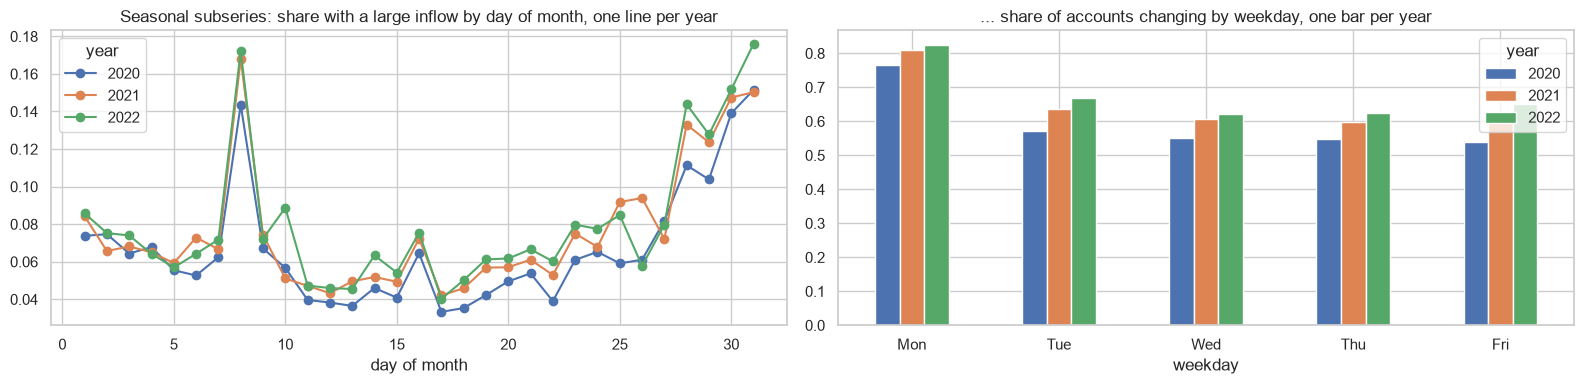

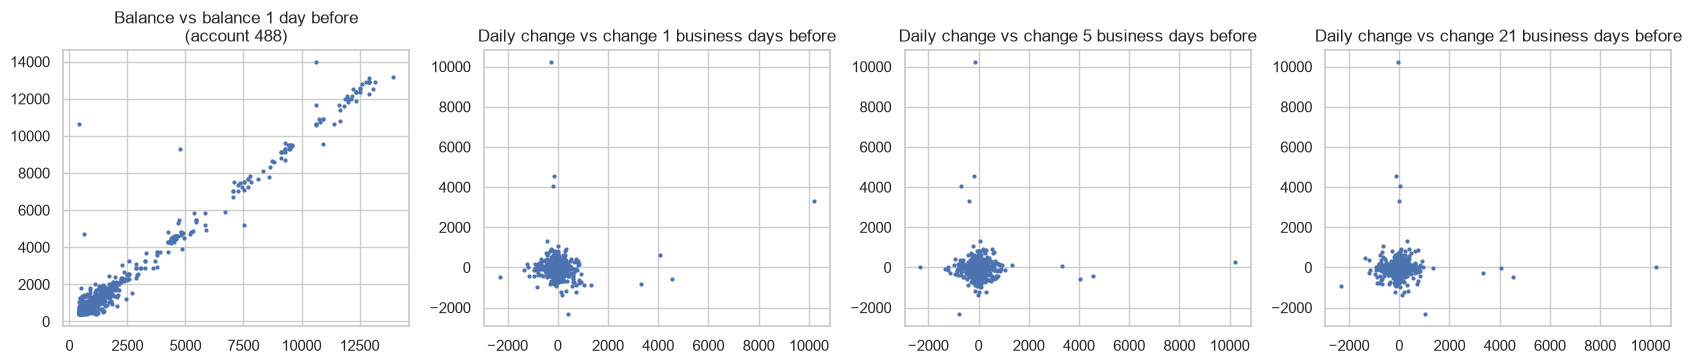

In [41]:
sub = cal[cal.weekday < 5].assign(year=lambda t: t.index.year)
subseries = sub.pivot_table(index="day", columns="year", values="large_inflow", aggfunc="mean")
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
subseries.plot(ax=axes[0], marker="o", title="Seasonal subseries: share with a large inflow by day of month, one line per year")
axes[0].set(xlabel="day of month")
wk = sub.pivot_table(index="weekday", columns="year", values="share_changing", aggfunc="mean").rename(index=dict(enumerate(weekday_names)))
wk.plot.bar(ax=axes[1], rot=0, title="... share of accounts changing by weekday, one bar per year")
plt.tight_layout(); plt.show()

lag_acc = bal.loc[per_account.share_days_changed.idxmax()].dropna()
lag_x = lag_acc.diff().dropna()
lag_x = lag_x[lag_x.index.dayofweek < 5]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
axes[0].scatter(lag_acc.shift(1), lag_acc, s=4); axes[0].set(title=f"Balance vs balance 1 day before\n(account {lag_acc.name})")
for ax, L in zip(axes[1:], (1, 5, 21)):
    ax.scatter(lag_x.shift(L), lag_x, s=4)
    ax.set(title=f"Daily change vs change {L} business days before")
plt.tight_layout(); plt.show()
save_result(subseries, "D21_subseries_large_inflow_by_day_year", "Share of accounts with a large inflow by day of month and year")
save_result(wk, "D21_subseries_activity_by_weekday_year", "Share of accounts changing by weekday and year")

The monthly pattern of large inflows is almost identical in the three years: the peak on the 8th and the rise at the
end of the month are there every year, so a seasonal pattern estimated on the past can be trusted for January 2023.
The weekday bars show the date-convention change from another angle: after realignment the three years agree, with
activity on business days only.

The lag plots tell the same story as the variance ratios. Today's balance sits on a straight line against
yesterday's, while today's change shows no visible relation with the change one, five or twenty-one business days
earlier.

## D22. Repeated patterns and the most unusual month

The matrix profile is a recent tool for mining time series. For every 30-day window of an account it finds the most
similar other window in the same account. A low distance means the window is a repeated pattern, a motif; the window
with the highest distance is the most unusual stretch of the account's history, its discord. Discords are natural
candidates for the anomalies we will study in Sprint 3, and motifs tell us how much of an account's history repeats
itself.

,motif_distance,discord_distance,share_windows_with_close_repeat
count,100.00,100.00,100.00
mean,0.49,4.96,0.34
std,0.27,0.61,0.20
min,0.00,2.96,0.00
25%,0.32,4.61,0.17
50%,0.48,4.92,0.33
75%,0.67,5.35,0.46
max,1.26,7.39,0.84


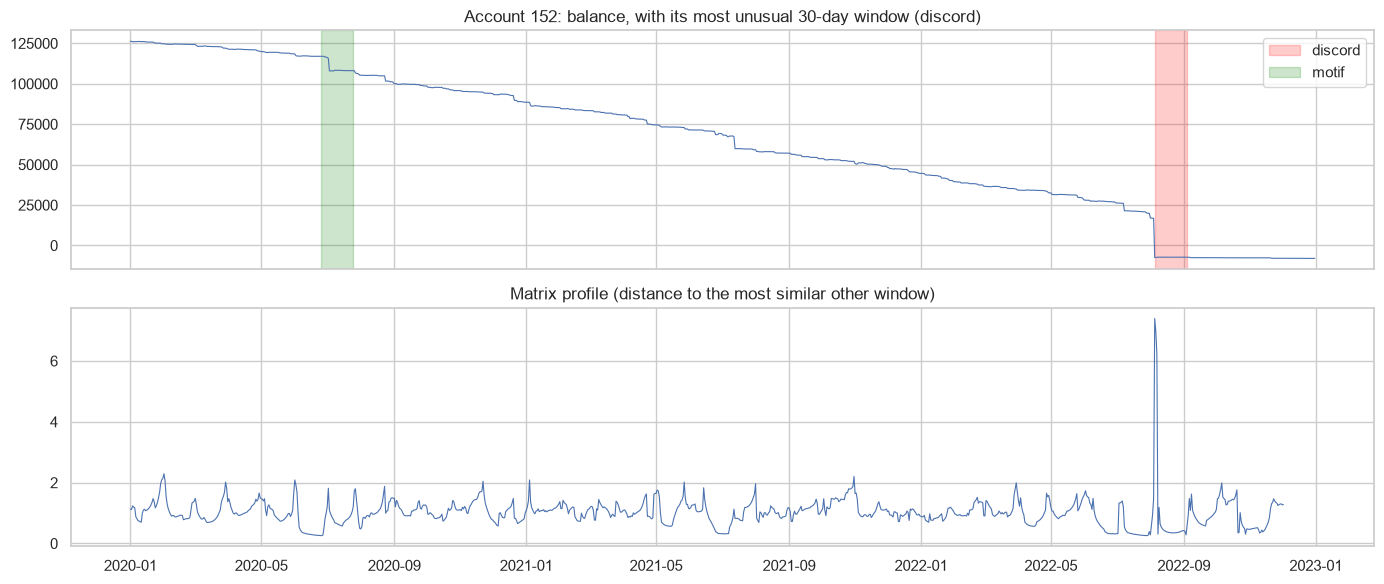

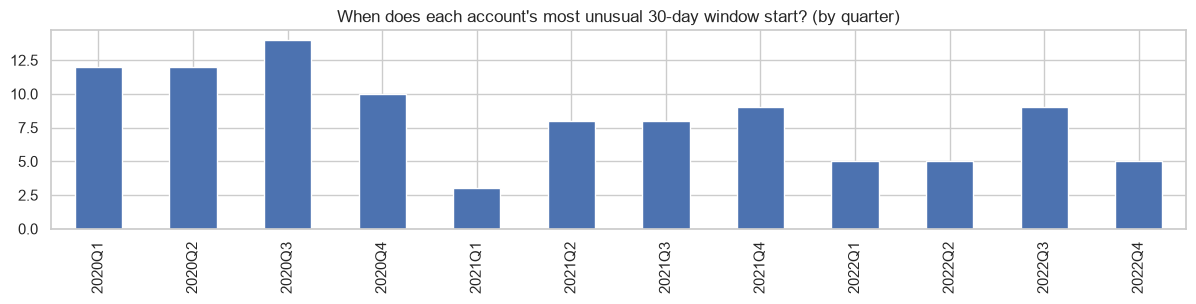

In [42]:
MP_WINDOW = 30
mp_ids = sample_accounts(bal.index, min(100, MAX_TEST_ACCOUNTS))
mp_rows, discord_dates = {}, []
for acc in mp_ids:
    s = bal.loc[acc].dropna()
    x = s.to_numpy().astype(float)
    if len(x) < 4 * MP_WINDOW or np.diff(x).std() == 0:
        continue
    profile = stumpy.stump(x, m=MP_WINDOW)[:, 0].astype(float)
    profile[~np.isfinite(profile)] = np.nan
    motif_i, discord_i = int(np.nanargmin(profile)), int(np.nanargmax(profile))
    discord_dates.append(s.index[discord_i])
    mp_rows[acc] = {"motif_start": s.index[motif_i], "motif_distance": profile[motif_i],
                    "discord_start": s.index[discord_i], "discord_distance": profile[discord_i],
                    "share_windows_with_close_repeat": float(np.nanmean(profile < 0.25 * np.sqrt(MP_WINDOW)))}
mp = pd.DataFrame(mp_rows).T
display(mp[["motif_distance", "discord_distance", "share_windows_with_close_repeat"]].astype(float).describe().round(2))

example_mp = mp.discord_distance.astype(float).idxmax()
s = bal.loc[example_mp].dropna(); x = s.to_numpy().astype(float)
prof = stumpy.stump(x, m=MP_WINDOW)[:, 0].astype(float)
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(s.index, x, lw=0.8); axes[0].set_title(f"Account {example_mp}: balance, with its most unusual 30-day window (discord)")
dstart = mp.loc[example_mp, "discord_start"]; mstart = mp.loc[example_mp, "motif_start"]
axes[0].axvspan(dstart, dstart + pd.Timedelta(days=MP_WINDOW), color="red", alpha=0.2, label="discord")
axes[0].axvspan(mstart, mstart + pd.Timedelta(days=MP_WINDOW), color="green", alpha=0.2, label="motif")
axes[0].legend()
axes[1].plot(s.index[:len(prof)], prof, lw=0.8); axes[1].set_title("Matrix profile (distance to the most similar other window)")
plt.tight_layout(); plt.show()
pd.Series(pd.to_datetime(discord_dates)).dt.to_period("Q").value_counts().sort_index().plot.bar(
    figsize=(12, 3.2), title="When does each account's most unusual 30-day window start? (by quarter)")
plt.tight_layout(); plt.show()
save_result(mp, "D22_matrix_profile_per_account", "Per account (sample): motif and discord (most unusual 30-day window) from the matrix profile")

For a typical account about a third of its 30-day windows have a close repetition somewhere else in its history, so
monthly shapes do recur, which is good news for models that learn from the past. The most unusual windows are spread
over the three years, with more of them in 2020, the first year of the pandemic and the start of several accounts.
Reassuringly, they do not cluster around August 2022: after our repair, the date-convention switch leaves no trace
in the data. The discords found here will be the starting point of the anomaly analysis in Sprint 3.

## D23. What the closer look taught us

The deeper analyses did not overturn the picture from Parts A to C; they sharpened it. The data looks like real money
(D1) and the accounts are independent of each other (D5), so we model them as separate series that share a calendar.
That calendar is more precise than we thought: inflows come at the end of the month and on the 8th, moved to the next
business day at weekends (D3), the monthly cycle needs several harmonics to be drawn (D6), it is stable from year to
year (D21) and too weak for seasonal differencing in most accounts (D17). Some payments return on fixed days and can
be projected (D2), while there are no credit limits to respect (D4).

The specialist tools changed how we see the dynamics. Day to day the balance looks like a random walk, but over a
month most of the movement cancels out (D18), and the apparent wandering is largely a stable level that jumps from
time to time (D7, D16). Flows are lumpy (D15), so forecasting the level is wiser than forecasting each movement. A
logarithm-like transformation such as asinh makes the accounts comparable (D19), and some non-linear structure is left
for machine-learning models (D20).

Above all, two findings will shape Sprint 2. The accounts split along one main line, their distance from zero (D14),
and the oracle showed that most of the official error comes from choosing the wrong level for the accounts that live
near zero (D10 to D12). Getting those accounts right is worth more than any refinement of the daily dynamics.

# Part E · From evidence to decisions

## 16. How we prepare the data

Each decision below comes from something we saw earlier in the notebook.

| Evidence | Decision |
|---|---|
| Until August 2022 each column holds the previous day's closing balance (§3) | Move those columns back one day and fill the single resulting weekend gap |
| 5 August 2022 holds the sum of two closing balances (§3) | Repair it exactly by subtracting the next day |
| Missing values only mark accounts opened later (§2) | No imputation; each account starts on its first day |
| Negative balances are frequent and legitimate (§5) | Keep them; forecasts may be negative; no log transform |
| Near-zero balances make MAPE explode (§5, D10–D12) | Report the official MAPE with its two companions; treat near-zero accounts separately in Sprint 2 |
| Big moves are mostly permanent level shifts (§6, D7) | Keep them; focus models on the recent regime |
| Account sizes differ by orders of magnitude (§4) | Scale each account before any model that learns across accounts |
| Weekly and monthly rhythms, holidays, the 8th (§7, D3, D6) | Calendar information: business days, day of month, end of month, the 8th moved to the next business day, holidays |
| Random walk day to day, but strong mean reversion over a month and level breaks (§10, §11, D16, D18) | Forecast the level around which the balance oscillates; ARIMA with d = 1 or local-level models that reset after breaks |
| Seasonal patterns stable but weak (D17, D21) | Calendar regressors or Fourier terms instead of seasonal differencing |
| Skewed scales, negatives (D19) | Scale per account and use asinh for global models; evaluate on the original scale |
| Two kinds of accounts: far from zero vs living around zero (D14) | Separate strategies per group in Sprint 2 |
| Accounts are independent (§14, D5) | No VAR; separate or global models with calendar information |

The prepared dataset keeps the shape of the original file: one row per account, one column per day, realigned and
repaired, with the late-starting accounts still empty before their first day.

In [43]:
prepared = bal.copy()
save_result(prepared.rename(columns=lambda c: c.strftime("%Y-%m-%d")), "16_prepared_balances",
            "PREPARED DATASET (wide, same layout as the raw file): realigned calendar, repaired 2022-08-05, leading NaN kept")
display(pd.Series({
    "accounts": prepared.shape[0],
    "days": prepared.shape[1],
    "first date": prepared.columns.min().date(),
    "last date": prepared.columns.max().date(),
    "missing (leading only)": int(prepared.isna().sum().sum()),
}).to_frame("prepared dataset"))

,prepared dataset
accounts,500
days,1096
first date,2020-01-01
last date,2022-12-31
missing (leading only),5853


## 17. The benchmark to beat

The last step of this sprint is to set the bar for Sprint 2. We mimic the real task with rolling-origin validation:
for each fold we keep only the data up to a cut-off date and forecast the next 30 days. The folds are the four last
30-day windows of 2022, which reflect the most recent behaviour, and January 2022, the same season as the real
forecast. We score four simple forecasts: the last balance, last week repeated, and the mean and median of the last 30
days.

In [44]:
def baselines(train):
    """Simple forecasts from the training matrix (accounts x days) for HORIZON days."""
    T = train.to_numpy()
    last_value = T[:, -1:]
    last_week = T[:, -7:]
    reps = int(np.ceil(HORIZON / 7))
    return {
        "naive (last value)": np.repeat(last_value, HORIZON, axis=1),
        "seasonal naive (last week)": np.tile(last_week, reps)[:, :HORIZON],
        "mean of last 30 days": np.repeat(np.nanmean(T[:, -30:], 1, keepdims=True), HORIZON, axis=1),
        "median of last 30 days": np.repeat(np.nanmedian(T[:, -30:], 1, keepdims=True), HORIZON, axis=1),
    }


results = []
for origin in origins:
    train, test = split(prepared, origin)
    for name, fc in baselines(train).items():
        results.append({"fold (test start)": (origin + pd.Timedelta(days=1)).date(), "model": name,
                        **evaluate(test.to_numpy(), fc, train.to_numpy())})
results = pd.DataFrame(results)
display(results.pivot(index="model", columns="fold (test start)", values="MAPE (official)").round(1))
summary = results.groupby("model")[METRICS].mean().sort_values(f"MAPE |actual|>={NEAR_ZERO:.0f}")
save_result(results, "17_baselines_by_fold", "Baseline forecasts: all metrics per fold and model", index=False)
save_result(summary, "17_baselines_summary", "Baseline forecasts: metrics averaged over folds (reference for Sprint 2)")
summary.round(1)

fold (test start),2022-01-01,2022-09-03,2022-10-03,2022-11-02,2022-12-02
model,,,,,
mean of last 30 days,812.4,519.3,723.2,3804.2,9023.9
median of last 30 days,593.5,314.2,334.3,3408.7,10512.6
naive (last value),768.3,652.4,794.9,3916.4,381.8
seasonal naive (last week),640.8,715.8,716.6,4368.7,299.0


,MAPE (official),median per-account MAPE,MAPE |actual|>=100
model,,,
median of last 30 days,3032.6,66.5,71.5
mean of last 30 days,2976.6,72.5,78.4
naive (last value),1302.7,68.8,88.7
seasonal naive (last week),1348.2,78.8,98.3


The official MAPE is huge for every simple forecast and jumps from fold to fold, driven by a few near-zero balances, as
section 5 predicted. The two companion measures are far lower and much more stable. The ranking also depends on the
measure: the last balance does best on the official score, while the median of the last 30 days does best on the
typical account and on balances above €100. Repeating last week's path is never the best, since it copies last
week's noise.

These numbers are the benchmark for Sprint 2. The disagreement between measures is itself a result: it confirms that
the near-zero accounts need their own strategy.

## 18. What we take into Sprint 2

We started with a clean-looking file and found that it hid two problems: a change in the date convention in August
2022 and one corrupted day. Both are now corrected, and without that correction every weekly pattern would have been
learned one day off. The missing values turned out to be accounts opened late, and need no treatment.

The balances follow a business-day week and a month shaped like a saw-tooth, with salaries at the end of the month,
pensions on the 8th and debits at the beginning. Day to day they look like random walks, but over a month most of
the movement cancels out around a level that jumps from time to time, and accounts are essentially independent of
each other. All of this
points towards models fitted to the recent history of each account, or global models with good calendar information,
evaluated on folds that include January.

The real difficulty, however, lies in the metric. A large share of balances lives near zero, and the oracle showed
that most of the official error comes from choosing the wrong level for those accounts. Sprint 2 will therefore have to
do two things well: model the rhythm of the ordinary accounts, and find a careful strategy for the ones that live
close to zero. The benchmark to beat is in section 17.

## 19. Where the results are saved

Every table in this notebook is also saved as a CSV file in `data/sprint1/`, so the results can be consulted without
running the notebook again. The file `00_index.csv` lists them all, and `00_account_features.csv` gathers every
per-account result in a single table, one row per account.

In [45]:
account_features = (per_account
                    .join(first_obs.rename("first_observation_raw_label"))
                    .join(pd.Series(sign_type, index=bal.index, name="sign_type"))
                    .join(pd.DataFrame({"extreme_moves": big.sum(1), "spikes": spike.sum(1)}, index=bal.index))
                    .join(st[["adf_p_level", "kpss_p_level", "levels", "first differences"]]
                          .rename(columns={"levels": "stationarity_levels", "first differences": "stationarity_diff"}))
                    .join(pd.DataFrame({"ljung_box_p_lag7": lb7, "ljung_box_p_lag30": lb30}, index=acf_ids))
                    .join(arch_p.rename("arch_lm_p"))
                    .join(strengths.add_prefix("mstl_strength_"))
                    .join(feat.add_suffix("_last12m"))
                    .join(naive_mape_acc)
                    .join(pcs).join(clusters.rename("feature_cluster"))
                    .join(sb_in[["ADI", "CV2", "category"]].add_prefix("inflow_"))
                    .join(sb_out[["ADI", "CV2", "category"]].add_prefix("outflow_"))
                    .join(za[["za_p", "break_date"]].rename(columns={"za_p": "zivot_andrews_p", "break_date": "zivot_andrews_break"}))
                    .join(vr[["VR 1 month (21)", "z 1 month (21)"]].rename(columns=lambda c: "variance_ratio_" + c))
                    .join(payday[["payday_mode", "calendar_day_concentration", "regular_payday"]])
                    .join(cp_table[["change_points", "days_since_last_change_point"]]))
save_result(account_features, "00_account_features", "ONE ROW PER ACCOUNT: all per-account statistics, tests and segment")

index = pd.DataFrame(saved_files)
if SAVE_RESULTS:
    index.to_csv(RESULTS_DIR / "00_index.csv", index=False)
    print(f"{len(index)} result files written to {RESULTS_DIR}")
index

77 result files written to C:\Users\manue\Desktop\mestrado\2026-2027\EQC\case-study-iii-millenium-bcp\data\sprint1


,file,description,rows,columns
0,01_structure.csv,"Dataset structure: size, date range, duplicates",9,1
1,02_missing_summary.csv,Missing values: totals by type (leading/traili...,7,1
2,02_first_observation.csv,Per account: first observed (raw) date and num...,500,2
3,03_change_share_month_weekday_raw.csv,Raw labels: share of accounts whose balance ch...,36,7
4,03_change_share_daily_raw.csv,Raw labels: share of accounts whose balance ch...,1094,1
...,...,...,...,...
72,D22_matrix_profile_per_account.csv,Per account (sample): motif and discord (most ...,100,5
73,16_prepared_balances.csv,"PREPARED DATASET (wide, same layout as the raw...",500,1096
74,17_baselines_by_fold.csv,Baseline forecasts: all metrics per fold and m...,20,5
75,17_baselines_summary.csv,Baseline forecasts: metrics averaged over fold...,4,3
